#### install ollama in order to use llama model

In [ ]:
!apt-get update -qq && apt-get install -y -qq zstd
!curl -fsSL https://ollama.com/install.sh | sh
!ollama --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package zstd.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [ ]:
import subprocess
import time
import requests

server = subprocess.Popen(
    ["ollama", "serve"],
    stdout=open("/tmp/ollama.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

response = requests.get("http://127.0.0.1:11434/api/tags", timeout=10)

print("Server status:", response.status_code)
print("Response:", response.json())

Server status: 200
Response: {'models': []}


#### Load RAG Dataset

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "nvidia/TechQA-RAG-Eval",
    split="train"
)

print("Number of samples:", len(dataset))
print("Columns:", dataset.column_names)

sample = dataset[0]

print("Question:", sample["question"])
print("Answer:", sample["answer"])
print("Answerable:", not sample["is_impossible"])

if sample["contexts"]:
    print("Source:", sample["contexts"][0]["filename"])
    print("Context:", sample["contexts"][0]["text"][:500])

README.md:   0%|          | 0.00/2.11k [00:00<?, ?B/s]

train.json:   0%|          | 0.00/4.02M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/910 [00:00<?, ? examples/s]

Number of samples: 910
Columns: ['id', 'question', 'answer', 'is_impossible', 'contexts']
Question: User environment variables no longer getting picked up after upgrade to 4.1.1.1 or 4.1.1.2?



Have you found that after upgrade to Streams 4.1.1.1 or 4.1.1.2, that environment variables set in your .bashrc are no longer being set? For example ODBCINI is not set for the database toolkit and you get

     An SQL operation failed. The SQL state is 08003, the SQL code
     is 0 and the SQL message is [unixODBC][Driver
     Manager]Connnection does not exist.

Answer: To work around the issue, set environment variables that are needed by the application directly in the instance with:  * 
   
 * streamtool setproperty
 * -d <domain> -i <instance>
   --application-ev <VARIABLE NAME>=<VARIABLE VALUE>
Answerable: True
Source: swg21996508.txt
Context: Title: IBM STREAMS 4.1.1.1 and 4.1.1.2  JOBS DO NOT INHERIT THE ENVIRONMENT VARIABLES SET IN .BASHRC, WHEN STREAMS IS RUN AS A SYSTEM SERVICE - Uni

###### load into pandas and remove duplicates and stuff

In [ ]:
import pandas as pd
import hashlib

df = dataset.to_pandas()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (910, 5)


,id,question,answer,is_impossible,contexts
0,TRAIN_Q000,User environment variables no longer getting p...,"To work around the issue, set environment vari...",False,"[{'filename': 'swg21996508.txt', 'text': 'Titl..."
1,TRAIN_Q001,Netcool/Impact (all versions): How is the Exit...,This is because the Exit() parser function in ...,False,"[{'filename': 'swg21675316.txt', 'text': 'Titl..."
2,TRAIN_Q002,Why are replies going to the DLQ with reason 2...,-,True,[]
3,TRAIN_Q003,How to configure SSL mutual authentication in ...,The following steps help guide you through the...,False,"[{'filename': 'swg21179559.txt', 'text': 'Titl..."
4,TRAIN_Q004,Help with Action required for IIB H.E. V9 & WM...,-,True,[]


In [ ]:
docs_df = df[["id", "contexts"]].explode(
    "contexts",
    ignore_index=True
)

total_contexts = docs_df["contexts"].notna().sum()# counting not Nan contexts

docs_df["filename"] = docs_df["contexts"].apply(
    lambda c: c.get("filename") if isinstance(c, dict) else None
)# if there was filename say if there wasn't return None

docs_df["text"] = docs_df["contexts"].apply(
    lambda c: c.get("text") if isinstance(c, dict) else None
)#

print("Total contexts:", total_contexts)

display(docs_df.head())

Total contexts: 610


,id,contexts,filename,text
0,TRAIN_Q000,"{'filename': 'swg21996508.txt', 'text': 'Title...",swg21996508.txt,Title: IBM STREAMS 4.1.1.1 and 4.1.1.2 JOBS D...
1,TRAIN_Q001,"{'filename': 'swg21675316.txt', 'text': 'Title...",swg21675316.txt,Title: IBM Exit() action within User Defined F...
2,TRAIN_Q002,NaN,None,None
3,TRAIN_Q003,"{'filename': 'swg21179559.txt', 'text': 'Title...",swg21179559.txt,Title: IBM Guide to properly setting up SSL wi...
4,TRAIN_Q004,NaN,None,None


In [ ]:
valid_docs = docs_df[
    docs_df["text"].apply(
        lambda x: isinstance(x, str) and bool(x.strip())
    )# we will keep the context that are string and have at least one char
].copy()

valid_docs["normalized_text"] = (
    valid_docs["text"].str.strip()
)# remove extra spaces

print("Valid documents:", len(valid_docs))
print("Invalid contexts:", total_contexts - len(valid_docs))

Valid documents: 610
Invalid contexts: 0


In [ ]:
def generate_hash(text: str) -> str:
    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


valid_docs["content_hash"] = (
    valid_docs["normalized_text"].apply(generate_hash)
)

In [ ]:
unique_docs = valid_docs.drop_duplicates(
    subset=["content_hash"]
).copy()

print("Total valid documents:", len(valid_docs))
print("Unique documents:", len(unique_docs))
print(
    "Duplicate occurrences:",
    len(valid_docs) - len(unique_docs)
)

Total valid documents: 610
Unique documents: 496
Duplicate occurrences: 114


In [ ]:
unique_docs = (
    valid_docs
    .groupby("content_hash", as_index=False)
    .agg(
        filename=("filename", "first"),
        text=("text", "first"),
        filenames=(
            "filename",
            lambda x: list(x.dropna().unique())
        ),
        question_ids=(
            "id",
            lambda x: list(x.dropna().unique())
        ),
        occurrence_count=("id", "size")
    )
)

In [ ]:
duplicate_docs = unique_docs[
    unique_docs["occurrence_count"] > 1
]

display(
    duplicate_docs[
        ["filename", "filenames", "question_ids", "occurrence_count", "text"]
    ].head(5)
)

,filename,filenames,question_ids,occurrence_count,text
6,swg22009818.txt,[swg22009818.txt],"[TRAIN_Q060, TRAIN_Q101, TRAIN_Q517]",3,Title: IBM Guardium STAP does not connect prop...
12,swg21451229.txt,[swg21451229.txt],"[TRAIN_Q067, DEV_Q038]",2,Title: IBM Rule Team Server/Decision Center is...
19,swg21972012.txt,[swg21972012.txt],"[TRAIN_Q492, TRAIN_Q533]",2,Title: IBM Security Bulletin: Malformed client...
20,swg21406783.txt,[swg21406783.txt],"[TRAIN_Q030, TRAIN_Q068, TRAIN_Q357]",3,Title: IBM When a Certificate Authority (CA) s...
21,swg21966637.txt,[swg21966637.txt],"[TRAIN_Q011, TRAIN_Q306]",2,Title: IBM Getting a warning message 'You do n...


In [ ]:
# انتخاب ۳ هش تکراری
sample_hashes = (
    unique_docs.loc[
        unique_docs["occurrence_count"] > 1,
        "content_hash"
    ]
    .head(3)
)

# نمایش تمام نسخه‌های مربوط به این هش‌ها
for i, h in enumerate(sample_hashes, 1):
    group = valid_docs[
        valid_docs["content_hash"] == h
    ]

    print(f"\n{'='*70}")
    print(f"Duplicate Group {i}")
    print(f"Occurrences: {len(group)}")

    for j, (_, row) in enumerate(group.iterrows(), 1):
        print(f"\n--- Occurrence {j} ---")
        print("Question ID:", row["id"])
        print("Filename:", row["filename"])
        print("Text:", repr(row["normalized_text"][:500]))


Duplicate Group 1
Occurrences: 3

--- Occurrence 1 ---
Question ID: TRAIN_Q060
Filename: swg22009818.txt
Text: 'Title: IBM Guardium STAP does not connect properly and does not show in the S-TAP Control - I see some specific errors in some log files. - United States\n\nText:\n TECHNOTE (FAQ)\n\nQUESTION\n What can cause an STAP to fail to connect properly - I get the following messages in the logs:-\n\n/tmp/guard_stap.stderr.txt on the DB Server :-\n"Server <ip_addr> wasn\'t heard from for nn sec during this attempt (nnn sec total), closing and re-opening"\n\nand from the Guardium Appliance - via fileserver in the /lo'

--- Occurrence 2 ---
Question ID: TRAIN_Q101
Filename: swg22009818.txt
Text: 'Title: IBM Guardium STAP does not connect properly and does not show in the S-TAP Control - I see some specific errors in some log files. - United States\n\nText:\n TECHNOTE (FAQ)\n\nQUESTION\n What can cause an STAP to fail to connect properly - I get the following messages in the logs:-\n\n/

#### check the length of contexts

In [ ]:
import numpy as np

# Calculate document lengths
unique_docs["char_length"] = (
    unique_docs["text"].str.len()
)

lengths = unique_docs["char_length"]

print("Total Documents:", len(unique_docs))
print("Average Length:", round(lengths.mean(), 2))
print("Minimum Length:", lengths.min())
print("Maximum Length:", lengths.max())
print("Median Length:", lengths.median())
print("95th Percentile:", np.percentile(lengths, 95))

Total Documents: 496
Average Length: 5592.46
Minimum Length: 318
Maximum Length: 178392
Median Length: 2849.0
95th Percentile: 16723.0


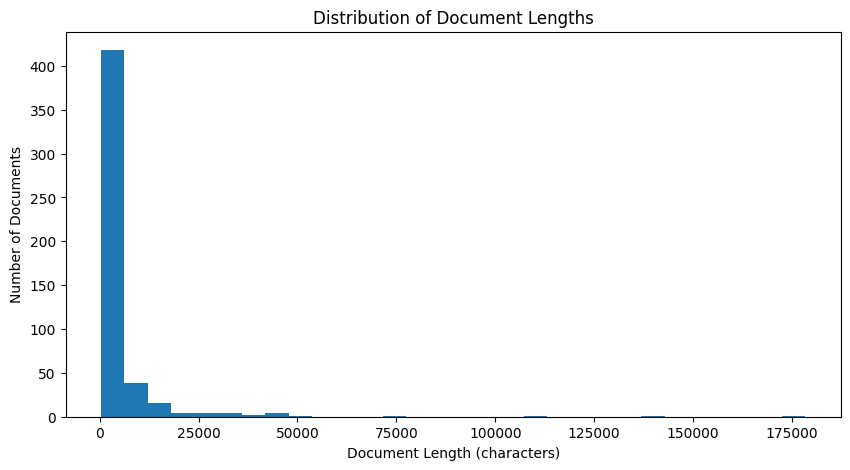

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    unique_docs["char_length"],
    bins=30
)

plt.xlabel("Document Length (characters)")
plt.ylabel("Number of Documents")
plt.title("Distribution of Document Lengths")

plt.show()

# lets clean the dataset

In [ ]:
import re

def clean_technical_text(text):
    if not isinstance(text, str):
        return ""

    # Standardize line endings
    text = text.replace("\r\n", "\n").replace("\r", "\n")

    # Normalize non-breaking spaces
    text = text.replace("\u00a0", " ").replace("\u202f", " ")

    # Remove trailing spaces/tabs from lines
    text = re.sub(r"[ \t]+(?=\n)", "", text)

    # Reduce excessive blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


# Keep the original text untouched
unique_docs["text_clean"] = unique_docs["text"].apply(clean_technical_text)

original = unique_docs["text"]
cleaned = unique_docs["text_clean"]

# Verify that only whitespace changed
content_preserved = all(
    re.sub(r"\s+", "", a) == re.sub(r"\s+", "", b)
    for a, b in zip(original, cleaned)
)

print("Total documents:", len(unique_docs))
print("Documents changed:", (original != cleaned).sum())
print("Total original characters:", original.str.len().sum())
print("Total cleaned characters:", cleaned.str.len().sum())
print("Non-whitespace content preserved:", content_preserved)

print("\nSample before:")
print(repr(original.iloc[0][:300]))

print("\nSample after:")
print(repr(cleaned.iloc[0][:300]))

Total documents: 496
Documents changed: 496
Total original characters: 2773861
Total cleaned characters: 2750918
Non-whitespace content preserved: True

Sample before:
'Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States\n\nText:\n256-bit ciphers; Strong Encryption; TLS 1.1; TLS 1.2; SSL; Generic Failure; Cannot support; RPT; RRT; T6; 71RRT-RPTPLAN; 71RRT-RPTINS; 71RRT-RPTCONF; 71RRT-RPTPLAY; 71RRT-RPTWV; 71RRT-RPTTS TECHNOTE (FAQ)\n\n'

Sample after:
'Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States\n\nText:\n256-bit ciphers; Strong Encryption; TLS 1.1; TLS 1.2; SSL; Generic Failure; Cannot support; RPT; RRT; T6; 71RRT-RPTPLAN; 71RRT-RPTINS; 71RRT-RPTCONF; 71RRT-RPTPLAY; 71RRT-RPTWV; 71RRT-RPTTS TECHNOTE (FAQ)\n\n'


# now we should use an LLM to do chunking

## do a test

In [ ]:
unique_docs

,content_hash,filename,text,filenames,question_ids,occurrence_count,char_length,text_clean
0,0040ccde89aea176c6f13b5064caef790e773261b4535f...,swg21960133.txt,Title: IBM Does the RRT agent support TLS 1.1/...,[swg21960133.txt],[TRAIN_Q590],1,7333,Title: IBM Does the RRT agent support TLS 1.1/...
1,00ff9b6b49f63d5a02a0af2ba3ad05b753c6a6b6de9f16...,swg21599258.txt,Title: IBM Installing IBM Tivoli Directory Ser...,[swg21599258.txt],[TRAIN_Q222],1,9602,Title: IBM Installing IBM Tivoli Directory Ser...
2,0101853d02e1d6fd2c8dc97621bd0db4059dd3dd763593...,swg21577379.txt,Title: IBM How to process an IBM SDK core dump...,[swg21577379.txt],[DEV_Q011],1,5909,Title: IBM How to process an IBM SDK core dump...
3,010c639e468fbdb57ca228c4439bdb4bd8f9f9a0703260...,swg21579319.txt,Title: IBM SelfMonitoring events incorrectly c...,[swg21579319.txt],[TRAIN_Q545],1,2372,Title: IBM SelfMonitoring events incorrectly c...
4,014a2ac501d197b13ea3701923673bdbd38835f2679081...,swg21608744.txt,Title: IBM Silent Install - United States\n\nT...,[swg21608744.txt],[DEV_Q186],1,1017,Title: IBM Silent Install - United States\n\nT...
...,...,...,...,...,...,...,...,...
491,fdbec9fed95235f364df0c00def20a4192051ba071eb16...,swg21978407.txt,Title: IBM File Formats for IBM Content Collec...,[swg21978407.txt],[TRAIN_Q384],1,876,Title: IBM File Formats for IBM Content Collec...
492,fdeee17afa873d32b0c831e67e4fa2041d96c9cc734bd8...,swg21974546.txt,Title: IBM BigFix Server unable to gather site...,[swg21974546.txt],[TRAIN_Q318],1,1818,Title: IBM BigFix Server unable to gather site...
493,ff0c2619641b070572a2ae53c5143ff91189796205195d...,swg22008622.txt,Title: IBM No data in some workspaces for MySQ...,[swg22008622.txt],[TRAIN_Q277],1,3666,Title: IBM No data in some workspaces for MySQ...
494,ff5e8db89d60ff9054aa60acfd388c045c611cc8d9eecc...,swg21965783.txt,Title: IBM QRadar: Enabling On Event and Flow ...,[swg21965783.txt],[DEV_Q102],1,1794,Title: IBM QRadar: Enabling On Event and Flow ...


In [ ]:
second_doc = unique_docs[
    unique_docs["text_clean"].str.len().between(3500, 5000)
].iloc[0]

second_text = second_doc["text_clean"].strip()

print("Document length:", len(second_text))
print("\nDocument preview:\n")
print(second_text[:1000])

Document length: 4785

Document preview:

Title: IBM Error # 2070. The license server is down. Specific symptom number: 3 - United States

Text:
 TECHNOTE (FAQ)

QUESTION
 We have network installations of IBM SPSS Statistics/Modeler. When the application is launched, the following errors are reported:

"The current license does not permit this job to continue."

followed by...

"Error # 2070
The license server is down. Please check to see that the license server is running or ask your local SPSS coordinator to check the license server.
This command is not executed.
Specific symptom number: 3."

The Safenet Sentinel License Manager has been licensed and confirmed to be running.
What is the problem?

CAUSE
The above error can be caused by invalid values entered during the licensing phase of installing SPSS Statistics/Modeler or the client machine cannot reach the Sentinel License Manager host using the machine Hostname.

ANSWER
Please do the following to verify:

1. Navigate to the IBM S

In [ ]:
!ollama pull qwen3:14b

In [ ]:
import requests
import json
import time
import subprocess
def make_prompt(text):
    how_many = max(1, round(len(text) / 800))
    return f"""
You split technical documents into meaningful chunks for a RAG Knowledge Base.

A chatbot will use these chunks to answer technical questions.

This document should probably be split into {how_many} chunks, but you can have more or less as appropriate.
There should be overlap between the chunks as appropriate; typically about 25% overlap or about 50 words,
so you have the same text in multiple chunks for best retrieval results.

Divide the document as you see fit, based on its meaning.
Keep information that depends on each other to be understood
or used correctly within the same chunk whenever possible.
Instead of returning the chunks, return only the exact text
that marks the beginning of each new chunk after the first.
the most important thing is you split docs based on their meaning.

Respond only as JSON:
{{"break_before": ["...", "..."]}}

Here is the document:

{text}
"""
prompt = make_prompt(second_text)

start = time.perf_counter()

response = requests.post(
    "http://127.0.0.1:11434/api/chat",
    json={
        "model": "qwen3:14b",
        "messages": [{"role": "user", "content": prompt}],
        "format": "json",
        "stream": False,
        "think": False,
        "keep_alive": "10m",
        "options": {
            "temperature": 0.1,
            "num_ctx": 4096,
            "num_predict": 512
        }
    },
    timeout=1200
)

response.raise_for_status()
data = response.json()
content = data["message"]["content"]

print("Time:", round(time.perf_counter() - start, 2), "seconds")
print("Finish reason:", data.get("done_reason"))
print("Generated tokens:", data.get("eval_count"))

try:
    result_mistral = json.loads(content)

    print(json.dumps(result_mistral, indent=2, ensure_ascii=False))

    boundaries = result_mistral["break_before"]
    positions = [second_text.find(b) for b in boundaries]

    valid = (
        set(result_mistral.keys()) == {"break_before"}
        and isinstance(boundaries, list)
        and all(isinstance(b, str) and second_text.count(b) == 1 for b in boundaries)
        and positions == sorted(set(positions))
        and all(p > 0 for p in positions)
    )

    print("Valid boundaries:", valid)

    if valid:
        points = [0] + positions + [len(second_text)]
        print("Chunk sizes:", [
            points[i + 1] - points[i]
            for i in range(len(points) - 1)
        ])
    else:
        print("Boundary positions:", positions)

except (json.JSONDecodeError, KeyError, TypeError) as e:
    print("Output error:", e)
    print("Raw output ending:", repr(content[-500:]))

print("\n--- GPU status ---")
print(subprocess.run(
    ["ollama", "ps"],
    capture_output=True,
    text=True
).stdout)

Time: 419.22 seconds
Finish reason: stop
Generated tokens: 40
{
  "break_before": [
    "ANSWER",
    "If the DaemonHost value specifies redundant license servers",
    "If the \"DaemonHost\" value is accurate",
    "RELATED INFORMATION",
    "Cross reference information"
  ]
}
Valid boundaries: True
Chunk sizes: [891, 548, 537, 2065, 359, 385]

--- GPU status ---
NAME         ID              SIZE     PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3:14b    bdbd181c33f2    10 GB    100% CPU     4096       llamacpp    9 minutes from now    



In [ ]:
def make_prompt(text):
    how_many = max(1, round(len(text) / 800))
    return f"""
You split technical documents into meaningful chunks for a RAG Knowledge Base.

A chatbot will use these chunks to answer technical questions.

This document should probably be split into {how_many} chunks, but you can have more or less as appropriate.
There should be overlap between the chunks as appropriate; typically about 25% overlap or about 50 words,
so you have the same text in multiple chunks for best retrieval results.

Divide the document as you see fit, based on its meaning.
Keep information that depends on each other to be understood
or used correctly within the same chunk whenever possible.
Instead of returning the chunks, return only the exact text
that marks the beginning of each new chunk after the first.
the most important thing is you split docs based on their meaning.

Respond only as JSON:
{{"break_before": ["...", "..."]}}

Here is the document:

{text}
"""

In [ ]:
import requests
import json
import time
third_doc = unique_docs[
    unique_docs["text_clean"].str.len().between(5200, 6500)
].iloc[0]

third_text = third_doc["text_clean"].strip()

start = time.perf_counter()
prompt = make_prompt(third_text)


response = requests.post(
    "http://127.0.0.1:11434/api/chat",
    json={
        "model": "qwen3:14b",
        "messages": [{"role": "user", "content": prompt}],
        "format": "json",
        "stream": False,
        "think": False,
        "keep_alive": "10m",
        "options": {
            "temperature": 0.1,
            "num_ctx": 4096,
            "num_predict": 512
        }
    },
    timeout=1200
)

response.raise_for_status()
data = response.json()
result = json.loads(data["message"]["content"])

boundaries = result["break_before"]

valid = (
    set(result) == {"break_before"}
    and isinstance(boundaries, list)
    and all(
        isinstance(b, str) and b and third_text.count(b) == 1
        for b in boundaries
    )
)

positions = [third_text.find(b) for b in boundaries] if valid else []

valid = valid and (
    positions == sorted(set(positions))
    and all(p > 0 for p in positions)
)

print("Document length:", len(third_text))
print("Time:", round(time.perf_counter() - start, 2), "seconds")
print("Boundaries:", json.dumps(boundaries, indent=2, ensure_ascii=False))
print("Valid boundaries:", valid)

if valid:
    points = [0] + positions + [len(third_text)]
    chunks = [
        third_text[points[i]:points[i + 1]]
        for i in range(len(points) - 1)
    ]

    print("Chunk sizes:", [len(c) for c in chunks])

    for i, chunk in enumerate(chunks, 1):
        print(f"\n{'=' * 20} CHUNK {i} {'=' * 20}")
        print(chunk)

Document length: 5809
Time: 648.06 seconds
Boundaries: [
  "PROBLEM(ABSTRACT)",
  "RESOLVING THE PROBLEM",
  "Locating the Core Dump",
  "Processing the Dump",
  "Determining the Java Directory",
  "Max Heap Size",
  "Files Generated",
  "Error Messages",
  "FAQ",
  "RELATED INFORMATION"
]
Valid boundaries: False


In [ ]:
print("Document length:", len(third_text))
print("\nDocument preview:\n")
print(third_text)

Document length: 5809

Document preview:

Title: IBM How to process an IBM SDK core dump with Jextract (AIX, Linux, Windows) - United States

Text:
crash; coredump; dumps; dump; dmp; dmps; jextracted; jextract; userdump; dtfj TECHNOTE (TROUBLESHOOTING)

PROBLEM(ABSTRACT)
 How do you process a raw core dump using Jextract?

Jextract is a tool provided with the IBM SDK to process and compress a core dump for later processing with tools such as DTFJ, which can be downloaded with IBM Support Assistant.

RESOLVING THE PROBLEM
You can process a core dump with Jextract, as long as the dump itself was produced by the IBM WebSphere Application Server JVM and is processed on the same system as the dump.

A processed dump can be used in both the Eclipse Memory Analyzer Tool [http://www.ibm.com/developerworks/java/jdk/tools/mat.html] and the DTFJ Dump Analyzer [http://www.ibm.com/developerworks/java/jdk/tools/dumpanalyzer/]. Both are included as downloadable tools from within IBM Support Assistant

In [ ]:
import requests
import json
import time

candidates = unique_docs[
    unique_docs["text_clean"].str.len().between(6500, 8500)
]

fourth_doc = candidates.sample(n=1, random_state=42).iloc[0]
fourth_text = fourth_doc["text_clean"].strip()

prompt = make_prompt(fourth_text)

start = time.perf_counter()

response = requests.post(
    "http://127.0.0.1:11434/api/chat",
    json={
        "model": "qwen3:14b",
        "messages": [{"role": "user", "content": prompt}],
        "format": "json",
        "stream": False,
        "think": False,
        "keep_alive": "10m",
        "options": {
            "temperature": 0.1,
            "num_ctx": 4096,
            "num_predict": 512
        }
    },
    timeout=1200
)

response.raise_for_status()
data = response.json()
result = json.loads(data["message"]["content"])

boundaries = result["break_before"]

valid = (
    set(result) == {"break_before"}
    and isinstance(boundaries, list)
    and all(
        isinstance(b, str) and b and fourth_text.count(b) == 1
        for b in boundaries
    )
)

positions = [fourth_text.find(b) for b in boundaries] if valid else []

valid = valid and (
    positions == sorted(set(positions))
    and all(p > 0 for p in positions)
)

print("Document length:", len(fourth_text))
print("Time:", round(time.perf_counter() - start, 2), "seconds")
print("Finish reason:", data.get("done_reason"))
print("Heading instruction active:",
      "Keep headings and introductory labels together" in prompt)
print("Valid boundaries:", valid)
print("Boundaries:", json.dumps(boundaries, indent=2, ensure_ascii=False))

if valid:
    points = [0] + positions + [len(fourth_text)]
    chunks = [
        fourth_text[points[i]:points[i + 1]]
        for i in range(len(points) - 1)
    ]

    print("Chunk sizes:", [len(c) for c in chunks])
    print("Original text preserved:", "".join(chunks) == fourth_text)

    for i, chunk in enumerate(chunks, 1):
        print(f"\n{'=' * 20} CHUNK {i} {'=' * 20}")
        print(chunk)

Document length: 7316
Time: 846.12 seconds
Finish reason: stop
Heading instruction active: False
Valid boundaries: True
Boundaries: [
  "ANSWER",
  "However, when a script uses TLS 1.2/1,2, some ciphers may not be supported.",
  "Do You Need to Patch Java?",
  "Patching JREs to Support TLS 1.1/1,2",
  "RELATED INFORMATION"
]
Chunk sizes: [715, 1008, 512, 2442, 2347, 292]
Original text preserved: True

==================== CHUNK 1 ====================
Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States

Text:
256-bit ciphers; Strong Encryption; TLS 1.1; TLS 1.2; SSL; Generic Failure; Cannot support; RPT; RRT; T6; 71RRT-RPTPLAN; 71RRT-RPTINS; 71RRT-RPTCONF; 71RRT-RPTPLAY; 71RRT-RPTWV; 71RRT-RPTTS TECHNOTE (FAQ)

QUESTION
 What do you need to do to configure the Robotic Response Time (RRT) agent to support TLS 1.1/1.2 and 256-bit ciphers?

CAUSE
Support for TLS 1.1/1.2 and 256-bit ciphers is determined by the underlying JRE (Java Runtime Environment). Co

In [ ]:
print("Document length:", len(fourth_text))
print("\nDocument preview:\n")
print(fourth_text)

Document length: 7316

Document preview:

Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States

Text:
256-bit ciphers; Strong Encryption; TLS 1.1; TLS 1.2; SSL; Generic Failure; Cannot support; RPT; RRT; T6; 71RRT-RPTPLAN; 71RRT-RPTINS; 71RRT-RPTCONF; 71RRT-RPTPLAY; 71RRT-RPTWV; 71RRT-RPTTS TECHNOTE (FAQ)

QUESTION
 What do you need to do to configure the Robotic Response Time (RRT) agent to support TLS 1.1/1.2 and 256-bit ciphers?

CAUSE
Support for TLS 1.1/1.2 and 256-bit ciphers is determined by the underlying JRE (Java Runtime Environment). Consequently, in order to support TLS 1.1/1.2 and 256-bit ciphers, patch the RPT workbench JRE, and patch the RRT agent JRE. Both JREs must support the same level of TLS.

ANSWER

SSL (Secure Sockets Layer) and TLS (Transport Layer Security) are transport layer protocols. Ciphers implement security by providing the encryption mechanism.

TLS is the new protocol. SSL protocol got up to version 3.0. In effect, TLS

#### as we saw it was good but some big chunkes that have relevant data, we should do some recursive splitting because we dont have any choice.

In [ ]:
from google.colab import drive
from pathlib import Path

import os
import json
import hashlib
import shutil
import subprocess
import pandas as pd

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/IBM_GraphRAG")

CHECKPOINT_DIR = BASE / "semantic_checkpoints"
BACKUP_DIR = BASE / "postgres_backups"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

BACKUP_FILE = BACKUP_DIR / "ibm_chunks.dump"
DATA_FILE = BASE / "unique_docs.pkl"

print("Google Drive folders ready")

Mounted at /content/drive
Google Drive folders ready


In [ ]:
if "unique_docs" in globals():
    unique_docs.to_pickle(DATA_FILE)
else:
    unique_docs = pd.read_pickle(DATA_FILE)

print("Documents available:", len(unique_docs))

Documents available: 496


#### install PostgreSQL on colab

In [ ]:
!apt-get update -qq
!apt-get install -y -qq postgresql postgresql-client
!pip -q install "psycopg[binary]" tqdm
!service postgresql start

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Preconfiguring packages ...
Selecting previously unselected package libjson-perl.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../00-libjson-perl_4.10000-1_all.deb ...
Unpacking libjson-perl (4.10000-1) ...
Selecting previously unselected package postgresql-client-common.
Preparing to unpack .../01-postgresql-client-common_257build1.1_all.deb ...
Unpacking postgresql-client-common (257build1.1) ...
Selecting previously unselected package ssl-cert.
Preparing to unpack .../02-ssl-cert_1.1.2ubuntu1_all.deb ...
Unpacking ssl-cert (1.1.2ubuntu1) ...
Selecting previously unselected package postgresql-common.
Preparing to unpack .../03-postgresql-common_257build1.1_all.deb ...
Adding 'diversion of /usr/bin/pg_config to /usr/bin/pg_config.libpq-dev by postgres

In [ ]:
import getpass
import psycopg

DB_NAME = "ibm_rag"
DB_USER = getpass.getuser()

def postgres_admin(*args):
    return subprocess.run(
        ["sudo", "-u", "postgres", *args],
        capture_output=True,
        text=True,
        check=True
    )

role_exists = postgres_admin(
    "psql", "-tAc",
    f"SELECT 1 FROM pg_roles WHERE rolname='{DB_USER}'"
).stdout.strip() == "1"

if not role_exists:
    postgres_admin("createuser", "-s", DB_USER)

db_exists = postgres_admin(
    "psql", "-tAc",
    f"SELECT 1 FROM pg_database WHERE datname='{DB_NAME}'"
).stdout.strip() == "1"

if not db_exists:
    postgres_admin("createdb", DB_NAME)

DATABASE_URL = f"postgresql:///{DB_NAME}?user={DB_USER}"

print("PostgreSQL is ready")

PostgreSQL is ready


In [ ]:
with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    tables_exist = conn.execute(
        "SELECT to_regclass('public.documents')"
    ).fetchone()[0] is not None

if not tables_exist and BACKUP_FILE.exists():
    print("Restoring PostgreSQL from Google Drive...")

    subprocess.run(
        [
            "pg_restore",
            "--exit-on-error",
            "--no-owner",
            "--no-acl",
            "--dbname", DATABASE_URL,
            str(BACKUP_FILE)
        ],
        check=True
    )

    print("Database restored successfully")

elif tables_exist:
    print("Existing database found")

else:
    print("New database; create tables using SCHEMA_SQL")

New database; create tables using SCHEMA_SQL


In [ ]:
def semantic_split_cached(text, session):

    config = {
        "model": MODEL,
        "num_ctx": NUM_CTX,
        "num_predict": NUM_PREDICT,
        "prompt": make_prompt(text)
    }

    config_bytes = json.dumps(
        config,
        ensure_ascii=False,
        sort_keys=True
    ).encode("utf-8")

    cache_key = hashlib.sha256(config_bytes).hexdigest()
    path = CHECKPOINT_DIR / f"{cache_key}.json"

    if path.exists():
        with open(path, "r", encoding="utf-8") as f:
            saved = json.load(f)

        spans = [tuple(x) for x in saved["spans"]]

        if (
            saved["text_sha256"] ==
            hashlib.sha256(text.encode("utf-8")).hexdigest()
            and "".join(text[a:b] for a, b in spans) == text
            and all(
                a < b and 0 <= a and b <= len(text)
                for a, b in spans
            )
            and all(
                spans[i][1] == spans[i + 1][0]
                for i in range(len(spans) - 1)
            )
            and spans[0][0] == 0
            and spans[-1][1] == len(text)
        ):
            print("Semantic checkpoint loaded")
            return spans

        raise ValueError("Invalid semantic checkpoint")

    # Run the original Qwen semantic chunker
    spans = semantic_split(text, session)

    payload = {
        "text_sha256": hashlib.sha256(
            text.encode("utf-8")
        ).hexdigest(),
        "model": MODEL,
        "spans": spans
    }

    temp_path = path.with_suffix(".json.tmp")

    with open(temp_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False)
        f.flush()
        os.fsync(f.fileno())

    os.replace(temp_path, path)

    print("Semantic checkpoint saved")

    return spans

In [ ]:
def backup_postgres():

    local_dump = Path("/content/ibm_chunks.dump")
    temp_drive_dump = BACKUP_DIR / "ibm_chunks.dump.tmp"

    # Create a consistent PostgreSQL backup locally
    subprocess.run(
        [
            "pg_dump",
            "-Fc",
            "--dbname", DATABASE_URL,
            "-f", str(local_dump)
        ],
        check=True
    )

    # Verify that the archive can be inspected
    subprocess.run(
        ["pg_restore", "--list", str(local_dump)],
        stdout=subprocess.DEVNULL,
        check=True
    )

    # Copy the completed archive to Drive
    shutil.copyfile(local_dump, temp_drive_dump)

    # Replace the previous backup
    os.replace(temp_drive_dump, BACKUP_FILE)

    print("PostgreSQL backup updated")

In [ ]:
SCHEMA_SQL = """
CREATE TABLE IF NOT EXISTS documents (
    document_id TEXT PRIMARY KEY,
    title TEXT,
    filename TEXT,
    filenames JSONB NOT NULL,
    question_ids JSONB NOT NULL,
    occurrence_count INTEGER NOT NULL DEFAULT 1,
    text_clean TEXT NOT NULL,
    model_name TEXT NOT NULL,
    prompt_version TEXT NOT NULL,
    created_at TIMESTAMPTZ DEFAULT NOW(),
    updated_at TIMESTAMPTZ DEFAULT NOW()
);

CREATE TABLE IF NOT EXISTS semantic_chunks (
    semantic_id UUID PRIMARY KEY,
    document_id TEXT NOT NULL
        REFERENCES documents(document_id) ON DELETE CASCADE,
    semantic_index INTEGER NOT NULL,
    content TEXT NOT NULL,
    char_start INTEGER NOT NULL,
    char_end INTEGER NOT NULL,
    UNIQUE(document_id, semantic_index)
);

CREATE TABLE IF NOT EXISTS retrieval_chunks (
    chunk_id UUID PRIMARY KEY,
    semantic_id UUID NOT NULL
        REFERENCES semantic_chunks(semantic_id) ON DELETE CASCADE,
    document_id TEXT NOT NULL
        REFERENCES documents(document_id) ON DELETE CASCADE,
    child_index INTEGER NOT NULL,
    content TEXT NOT NULL,
    char_start INTEGER NOT NULL,
    char_end INTEGER NOT NULL,
    split_method TEXT NOT NULL,
    UNIQUE(semantic_id, child_index)
);

CREATE INDEX IF NOT EXISTS idx_semantic_doc
    ON semantic_chunks(document_id);

CREATE INDEX IF NOT EXISTS idx_retrieval_doc
    ON retrieval_chunks(document_id);

CREATE INDEX IF NOT EXISTS idx_retrieval_parent
    ON retrieval_chunks(semantic_id);
"""

with psycopg.connect(DATABASE_URL) as conn:
    conn.execute(SCHEMA_SQL)

print("PostgreSQL tables created successfully")

PostgreSQL tables created successfully


In [ ]:
with psycopg.connect(DATABASE_URL) as conn:

    tables = conn.execute("""
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema = 'public'
          AND table_name IN (
              'documents',
              'semantic_chunks',
              'retrieval_chunks'
          )
        ORDER BY table_name
    """).fetchall()

    print("Existing tables:")

    for table in tables:
        print("✓", table[0])

    assert len(tables) == 3, "Some tables are missing!"

Existing tables:
✓ documents
✓ retrieval_chunks
✓ semantic_chunks


In [ ]:
import psycopg

with psycopg.connect(DATABASE_URL) as conn:
    info = conn.execute("""
        SELECT
            current_database(),
            current_schema(),
            to_regclass('public.documents')
    """).fetchone()

    print("Database:", info[0])
    print("Schema:", info[1])
    print("Documents table:", info[2])

Database: ibm_rag
Schema: public
Documents table: None


In [ ]:
import psycopg
import requests

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    with requests.Session() as session:

        for _, row in unique_docs.iterrows():

            doc_id = str(row["content_hash"])

            # Skip already processed documents
            exists = conn.execute(
                "SELECT EXISTS(SELECT 1 FROM documents WHERE document_id = %s)",
                (doc_id,)
            ).fetchone()[0]

            if exists:
                continue

            print("=" * 65)
            print("PROCESSING DOCUMENT:", doc_id[:12])
            print("TEXT LENGTH:", len(row["text_clean"]))
            print("=" * 65)

            try:
                result = save_document(row, conn, session)

                print("\n✅ SUCCEEDED - Saved to PostgreSQL")
                print("Semantic chunks:", result["semantic_chunks"])
                print("Retrieval chunks:", result["retrieval_chunks"])

                # Read back saved chunks
                chunks_info = conn.execute("""
                    SELECT
                        s.semantic_index,
                        r.child_index,
                        LENGTH(s.content),
                        LENGTH(r.content),
                        r.split_method
                    FROM retrieval_chunks r
                    JOIN semantic_chunks s
                        ON r.semantic_id = s.semantic_id
                    WHERE r.document_id = %s
                    ORDER BY s.semantic_index, r.child_index
                """, (doc_id,)).fetchall()

                print("\n--- SAVED CHUNKS ---")

                for semantic_idx, child_idx, parent_len, child_len, method in chunks_info:
                    print(
                        f"Parent {semantic_idx + 1} ({parent_len} chars)"
                        f" -> Child {child_idx + 1} ({child_len} chars)"
                        f" [{method}]"
                    )

                try:
                    backup_postgres()
                    print("\n✅ BACKUP SUCCEEDED - Google Drive")
                except Exception as backup_error:
                    print("\n❌ BACKUP FAILED:", backup_error)

            except Exception as e:
                print("\n❌ FAILED:", str(e))

            break

        else:
            print("All documents are already processed!")

PROCESSING DOCUMENT: 0040ccde89ae
TEXT LENGTH: 7316

❌ FAILED: name 'save_document' is not defined


In [ ]:
required_functions = [
    "make_prompt",
    "semantic_split",
    "semantic_split_cached",
    "paragraph_split",
    "save_document",
    "backup_postgres"
]

for name in required_functions:
    if name in globals() and callable(globals()[name]):
        print(f"✅ {name}: READY")
    else:
        print(f"❌ {name}: NOT DEFINED")

✅ make_prompt: READY
❌ semantic_split: NOT DEFINED
✅ semantic_split_cached: READY
❌ paragraph_split: NOT DEFINED
❌ save_document: NOT DEFINED
✅ backup_postgres: READY


In [ ]:
import requests
import json
import re

def semantic_split(text, session):

    prompt = make_prompt(text)

    response = session.post(
        "http://127.0.0.1:11434/api/chat",
        json={
            "model": "qwen3:14b",
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "format": "json",
            "stream": False,
            "think": False,
            "keep_alive": "10m",
            "options": {
                "temperature": 0,
                "num_ctx": 4096,
                "num_predict": 512
            }
        },
        timeout=1200
    )

    response.raise_for_status()
    data = response.json()

    if data.get("done_reason") != "stop":
        raise ValueError("LLM response incomplete")

    result = json.loads(data["message"]["content"])

    if set(result.keys()) != {"break_before"}:
        raise ValueError("Invalid JSON structure")

    boundaries = result["break_before"]

    if not isinstance(boundaries, list):
        raise ValueError("Invalid boundaries list")

    positions = []

    for boundary in boundaries:

        if not isinstance(boundary, str) or not boundary.strip():
            raise ValueError("Invalid boundary")

        matches = list(re.finditer(re.escape(boundary), text))

        if len(matches) == 1:
            pos = matches[0].start()

        else:
            # Handle repeated heading names like FAQ
            heading_matches = list(re.finditer(
                r"(?m)^[ \t]*" + re.escape(boundary) + r"[ \t]*$",
                text
            ))

            if len(heading_matches) != 1:
                raise ValueError(
                    f"Ambiguous boundary: {boundary[:80]}"
                )

            pos = heading_matches[0].start()

        positions.append(pos)

    if (
        positions != sorted(set(positions))
        or any(p <= 0 or p >= len(text) for p in positions)
    ):
        raise ValueError("Invalid boundary positions")

    points = [0] + positions + [len(text)]

    spans = [
        (points[i], points[i + 1])
        for i in range(len(points) - 1)
    ]

    assert "".join(text[a:b] for a, b in spans) == text

    return spans


print("✅ semantic_split: READY")

✅ semantic_split: READY


In [ ]:
import re
from bisect import bisect_right

def paragraph_split(text, max_chars=800):

    if not isinstance(text, str):
        raise TypeError("Text must be a string")

    if max_chars <= 0:
        raise ValueError("max_chars must be positive")

    if not text:
        return []

    if len(text) <= max_chars:
        return [text]

    # Find possible splitting positions
    boundaries = {
        "paragraph": [
            m.end()
            for m in re.finditer(r"\n[ \t]*\n+", text)
        ],
        "line": [
            m.end()
            for m in re.finditer(r"\n", text)
        ],
        "space": [
            m.end()
            for m in re.finditer(r"[ \t]+", text)
        ]
    }

    chunks = []
    start = 0

    while start < len(text):

        limit = min(start + max_chars, len(text))

        if limit == len(text):
            end = limit

        else:
            end = None

            for kind in ["paragraph", "line", "space"]:

                positions = boundaries[kind]

                idx = bisect_right(positions, limit) - 1

                if idx >= 0:
                    candidate = positions[idx]

                    # Avoid unnecessarily tiny chunks
                    if candidate >= start + max_chars // 2:
                        end = candidate
                        break

            # Last resort: hard split
            if end is None:
                end = limit

        chunks.append(text[start:end])
        start = end

    # Validation
    assert "".join(chunks) == text
    assert all(0 < len(c) <= max_chars for c in chunks)

    return chunks


print("✅ paragraph_split: READY")

✅ paragraph_split: READY


In [ ]:
import uuid
import psycopg
from psycopg.types.json import Jsonb

MODEL = globals().get("MODEL", "qwen3:14b")
NUM_CTX = globals().get("NUM_CTX", 4096)
NUM_PREDICT = globals().get("NUM_PREDICT", 512)
PROMPT_VERSION = globals().get("PROMPT_VERSION", "semantic_v1")

MAX_CHARS = 800


def save_document(row, conn, session):

    if not conn.autocommit:
        raise ValueError("Use PostgreSQL connection with autocommit=True")

    # Check database tables before running LLM
    for table in ["documents", "semantic_chunks", "retrieval_chunks"]:
        exists = conn.execute(
            "SELECT to_regclass(%s)",
            (f"public.{table}",)
        ).fetchone()[0]

        if exists is None:
            raise ValueError(f"Missing PostgreSQL table: {table}")

    text = row["text_clean"]
    document_id = str(row["content_hash"])

    if not isinstance(text, str) or not text.strip():
        raise ValueError("Document text is empty")

    # STEP 1: Semantic Chunking (with checkpoint)
    spans = semantic_split_cached(text, session)

    if (
        not spans
        or spans[0][0] != 0
        or spans[-1][1] != len(text)
        or any(
            a >= b or a < 0 or b > len(text)
            for a, b in spans
        )
        or any(
            spans[i][1] != spans[i + 1][0]
            for i in range(len(spans) - 1)
        )
    ):
        raise ValueError("Invalid semantic spans")

    # STEP 2: Prepare Parent and Child chunks
    parent_rows = []
    child_rows = []

    for semantic_index, (start, end) in enumerate(spans):

        semantic_text = text[start:end]

        semantic_id = uuid.uuid5(
            uuid.NAMESPACE_URL,
            f"{document_id}:semantic:{semantic_index}"
        )

        parent_rows.append((
            semantic_id,
            document_id,
            semantic_index,
            semantic_text,
            start,
            end
        ))

        if len(semantic_text) <= MAX_CHARS:
            children = [semantic_text]
            method = "semantic"
        else:
            children = paragraph_split(
                semantic_text,
                MAX_CHARS
            )
            method = "paragraph"

        assert "".join(children) == semantic_text

        child_start = start

        for child_index, child_text in enumerate(children):

            child_end = child_start + len(child_text)

            chunk_id = uuid.uuid5(
                uuid.NAMESPACE_URL,
                f"{document_id}:semantic:{semantic_index}:child:{child_index}"
            )

            assert text[child_start:child_end] == child_text
            assert 0 < len(child_text) <= MAX_CHARS

            child_rows.append((
                chunk_id,
                semantic_id,
                document_id,
                child_index,
                child_text,
                child_start,
                child_end,
                method
            ))

            child_start = child_end

        assert child_start == end

    # STEP 3: Prepare metadata
    title = text.splitlines()[0].removeprefix("Title:").strip()

    filenames = [
        str(x) for x in row["filenames"]
    ]

    question_ids = [
        str(x) for x in row["question_ids"]
    ]

    filename = row["filename"]
    if not isinstance(filename, str):
        filename = None

    # STEP 4: Save atomically in PostgreSQL
    with conn.transaction():

        conn.execute("""
            INSERT INTO documents (
                document_id, title, filename,
                filenames, question_ids,
                occurrence_count, text_clean,
                model_name, prompt_version
            )
            VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
            ON CONFLICT (document_id)
            DO UPDATE SET
                title = EXCLUDED.title,
                filename = EXCLUDED.filename,
                filenames = EXCLUDED.filenames,
                question_ids = EXCLUDED.question_ids,
                occurrence_count = EXCLUDED.occurrence_count,
                text_clean = EXCLUDED.text_clean,
                model_name = EXCLUDED.model_name,
                prompt_version = EXCLUDED.prompt_version,
                updated_at = NOW()
        """, (
            document_id,
            title,
            filename,
            Jsonb(filenames),
            Jsonb(question_ids),
            int(row["occurrence_count"]),
            text,
            MODEL,
            PROMPT_VERSION
        ))

        # Replace old chunks if document is reprocessed
        conn.execute(
            "DELETE FROM semantic_chunks WHERE document_id = %s",
            (document_id,)
        )

        with conn.cursor() as cur:

            cur.executemany("""
                INSERT INTO semantic_chunks (
                    semantic_id, document_id,
                    semantic_index, content,
                    char_start, char_end
                )
                VALUES (%s, %s, %s, %s, %s, %s)
            """, parent_rows)

            cur.executemany("""
                INSERT INTO retrieval_chunks (
                    chunk_id, semantic_id, document_id,
                    child_index, content,
                    char_start, char_end, split_method
                )
                VALUES (%s, %s, %s, %s, %s, %s, %s, %s)
            """, child_rows)

    return {
        "document_id": document_id,
        "semantic_chunks": len(parent_rows),
        "retrieval_chunks": len(child_rows),
        "parent_sizes": [
            len(p[3]) for p in parent_rows
        ],
        "child_sizes": [
            len(c[4]) for c in child_rows
        ]
    }


print("✅ save_document: READY")

✅ save_document: READY


In [ ]:
import psycopg
import requests

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    with requests.Session() as session:

        for _, row in unique_docs.iterrows():

            doc_id = str(row["content_hash"])

            # Skip already saved documents
            exists = conn.execute(
                """
                SELECT EXISTS(
                    SELECT 1 FROM documents
                    WHERE document_id = %s
                )
                """,
                (doc_id,)
            ).fetchone()[0]

            if exists:
                continue

            print("=" * 65)
            print("PROCESSING DOCUMENT:", doc_id[:12])
            print("DOCUMENT LENGTH:", len(row["text_clean"]))
            print("=" * 65)

            try:
                # Semantic + Paragraph Chunking + PostgreSQL
                result = save_document(row, conn, session)

                # Verify stored chunks
                saved_chunks = conn.execute(
                    """
                    SELECT
                        s.semantic_index,
                        r.child_index,
                        LENGTH(s.content),
                        LENGTH(r.content),
                        r.split_method
                    FROM retrieval_chunks r
                    JOIN semantic_chunks s
                        ON r.semantic_id = s.semantic_id
                    WHERE r.document_id = %s
                    ORDER BY
                        s.semantic_index,
                        r.child_index
                    """,
                    (doc_id,)
                ).fetchall()

                assert len(saved_chunks) == result["retrieval_chunks"]
                assert all(c[3] <= 800 for c in saved_chunks)

                print("\n✅ SUCCEEDED - Saved to PostgreSQL")
                print("Semantic chunks:", result["semantic_chunks"])
                print("Retrieval chunks:", result["retrieval_chunks"])

                print("\n--- SAVED CHUNK STRUCTURE ---")

                for parent_idx, child_idx, parent_len, child_len, method in saved_chunks:
                    print(
                        f"Parent {parent_idx + 1} ({parent_len} chars)"
                        f" -> Child {child_idx + 1} ({child_len} chars)"
                        f" [{method}]"
                    )

                # Backup to Google Drive
                try:
                    backup_postgres()
                    print("\n✅ BACKUP SUCCEEDED - Google Drive")
                except Exception as e:
                    print("\n⚠️ DATABASE SAVED, BUT BACKUP FAILED")
                    print("Backup error:", str(e))

            except Exception as e:
                print("\n❌ FAILED:", str(e))

            break

        else:
            print("✅ All documents are already saved!")

PROCESSING DOCUMENT: 0040ccde89ae
DOCUMENT LENGTH: 7316
Semantic checkpoint saved

✅ SUCCEEDED - Saved to PostgreSQL
Semantic chunks: 9
Retrieval chunks: 14

--- SAVED CHUNK STRUCTURE ---
Parent 1 (715 chars) -> Child 1 (715 chars) [semantic]
Parent 2 (619 chars) -> Child 1 (619 chars) [semantic]
Parent 3 (389 chars) -> Child 1 (389 chars) [semantic]
Parent 4 (512 chars) -> Child 1 (512 chars) [semantic]
Parent 5 (734 chars) -> Child 1 (734 chars) [semantic]
Parent 6 (295 chars) -> Child 1 (295 chars) [semantic]
Parent 7 (1413 chars) -> Child 1 (552 chars) [paragraph]
Parent 7 (1413 chars) -> Child 2 (764 chars) [paragraph]
Parent 7 (1413 chars) -> Child 3 (97 chars) [paragraph]
Parent 8 (2347 chars) -> Child 1 (659 chars) [paragraph]
Parent 8 (2347 chars) -> Child 2 (656 chars) [paragraph]
Parent 8 (2347 chars) -> Child 3 (627 chars) [paragraph]
Parent 8 (2347 chars) -> Child 4 (405 chars) [paragraph]
Parent 9 (292 chars) -> Child 1 (292 chars) [semantic]
PostgreSQL backup updated

✅ 

In [ ]:
import psycopg

DOC_PREFIX = "0040ccde89ae"

with psycopg.connect(DATABASE_URL) as conn:

    rows = conn.execute("""
        SELECT
            d.document_id,
            d.title,
            s.semantic_index,
            s.content AS parent_text,
            r.child_index,
            r.content AS child_text,
            r.split_method
        FROM documents d
        JOIN semantic_chunks s
            ON d.document_id = s.document_id
        JOIN retrieval_chunks r
            ON s.semantic_id = r.semantic_id
        WHERE d.document_id LIKE %s
        ORDER BY s.semantic_index, r.child_index
    """, (DOC_PREFIX + "%",)).fetchall()

if not rows:
    print("❌ Document not found in PostgreSQL")

else:
    print("✅ DOCUMENT LOADED FROM POSTGRESQL")
    print("Title:", rows[0][1])
    print("Total retrieval chunks:", len(rows))

    current_parent = None

    for row in rows:
        doc_id, title, parent_idx, parent_text, child_idx, child_text, method = row

        if parent_idx != current_parent:
            current_parent = parent_idx

            print("\n" + "=" * 85)
            print(f"SEMANTIC PARENT {parent_idx + 1}")
            print(f"Length: {len(parent_text)} characters")
            print("=" * 85)
            print(parent_text)

        print("\n" + "-" * 65)
        print(
            f"CHILD {child_idx + 1} | "
            f"{len(child_text)} chars | "
            f"Method: {method}"
        )
        print("-" * 65)
        print(child_text)

✅ DOCUMENT LOADED FROM POSTGRESQL
Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States
Total retrieval chunks: 14

SEMANTIC PARENT 1
Length: 715 characters
Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States

Text:
256-bit ciphers; Strong Encryption; TLS 1.1; TLS 1.2; SSL; Generic Failure; Cannot support; RPT; RRT; T6; 71RRT-RPTPLAN; 71RRT-RPTINS; 71RRT-RPTCONF; 71RRT-RPTPLAY; 71RRT-RPTWV; 71RRT-RPTTS TECHNOTE (FAQ)

QUESTION
 What do you need to do to configure the Robotic Response Time (RRT) agent to support TLS 1.1/1.2 and 256-bit ciphers?

CAUSE
Support for TLS 1.1/1.2 and 256-bit ciphers is determined by the underlying JRE (Java Runtime Environment). Consequently, in order to support TLS 1.1/1.2 and 256-bit ciphers, patch the RPT workbench JRE, and patch the RRT agent JRE. Both JREs must support the same level of TLS.



-----------------------------------------------------------------
CHILD 1 | 715 chars | Metho

In [ ]:
import re
import psycopg

def paragraph_split_v2(text, max_chars=800):

    def split_long_line(line):
        parts = []

        while len(line) > max_chars:
            # Balance the last two pieces
            target = (
                len(line) // 2
                if len(line) <= 2 * max_chars
                else max_chars
            )

            low = max(1, target - 120)
            high = min(max_chars, target + 120)

            # Prefer technical separators and whitespace
            candidates = [
                m.end()
                for m in re.finditer(r"[| \t]", line[:high])
                if m.end() >= low
            ]

            cut = (
                min(candidates, key=lambda x: abs(x - target))
                if candidates
                else target
            )

            parts.append(line[:cut])
            line = line[cut:]

        if line:
            parts.append(line)

        return parts

    cuts = [0] + [
        m.end()
        for m in re.finditer(r"\n[ \t]*\n+", text)
    ] + [len(text)]

    paragraphs = [
        text[a:b]
        for a, b in zip(cuts, cuts[1:])
        if a < b
    ]

    chunks = []
    current = ""

    for paragraph in paragraphs:
        if len(paragraph) <= max_chars:
            units = [paragraph]
        else:
            units = [
                part
                for line in paragraph.splitlines(keepends=True)
                for part in split_long_line(line)
            ]

        for unit in units:
            if current and len(current) + len(unit) > max_chars:
                chunks.append(current)
                current = ""

            current += unit

    if current:
        chunks.append(current)

    assert "".join(chunks) == text
    assert all(0 < len(c) <= max_chars for c in chunks)

    return chunks


# Load Semantic Parent 7 from PostgreSQL
with psycopg.connect(DATABASE_URL) as conn:
    parent_text = conn.execute("""
        SELECT content
        FROM semantic_chunks
        WHERE document_id LIKE %s
          AND semantic_index = 6
    """, ("0040ccde89ae%",)).fetchone()[0]

new_children = paragraph_split_v2(parent_text)

print("Original parent length:", len(parent_text))
print("New child sizes:", [len(c) for c in new_children])

for i, child in enumerate(new_children, 1):
    print(f"\n{'='*60}")
    print(f"CHILD {i} | {len(child)} characters")
    print("START:", repr(child[:100]))
    print("END:", repr(child[-100:]))

print("\nContent preserved:", "".join(new_children) == parent_text)

Original parent length: 1413
New child sizes: [552, 429, 432]

CHILD 1 | 552 characters
START: 'Playback Symptoms\n\nCheck whether your script playbacks indicate that the RRT JRE needs to be patched'
END: 'D3DD067D\n\nAdditional Details: none\n\n2) The trace-robotic log includes messages like the following:\n\n'

CHILD 2 | 429 characters
START: '[2015-05-05T22:10:58.487-04:00] - MIN - <playback-hostname> - PlaybackThreadPoolWorker-1169 - com.ib'
END: 'TTPPageVerdict|,eventId=|516.b32|,parentEventId=|516.b27|,ownerId=|A1E4ED99F22F68E2FD5CB86461633031|'

CHILD 3 | 432 characters
START: ",text=|Error occurred during connection to server '<server-url>'. Explanation message: 'Cannot suppo"
END: 'st verdict|,actualValue=||,expectedValue=|null|,eventVerdict=|3|,eventReason=|2|,eventDesc=|null||\n\n'

Content preserved: True


In [ ]:
import re
import math

def paragraph_split_v2(text, max_chars=800):

    if len(text) <= max_chars:
        return [text] if text else []

    def split_long_line(line):

        parts = []

        while len(line) > max_chars:

            # Number of pieces needed
            n = math.ceil(len(line) / max_chars)

            # Balanced target size
            target = math.ceil(len(line) / n)

            low = max(1, target - 100)
            high = min(max_chars, target + 100)

            candidates = [
                m.end()
                for m in re.finditer(
                    r"[ \t]+|\|",
                    line[:high]
                )
                if low <= m.end() <= high
            ]

            cut = (
                min(candidates, key=lambda p: abs(p - target))
                if candidates
                else target
            )

            parts.append(line[:cut])
            line = line[cut:]

        if line:
            parts.append(line)

        return parts

    # Identify original paragraph boundaries
    cuts = [0]

    for m in re.finditer(r"\n[ \t]*\n+", text):
        cuts.append(m.end())

    cuts.append(len(text))

    paragraphs = [
        text[a:b]
        for a, b in zip(cuts, cuts[1:])
        if a < b
    ]

    chunks = []
    current = ""

    for paragraph in paragraphs:

        if len(paragraph) <= max_chars:
            units = [paragraph]
        else:
            units = []

            for line in paragraph.splitlines(keepends=True):
                units.extend(split_long_line(line))

        for unit in units:

            if current and len(current) + len(unit) > max_chars:
                chunks.append(current)
                current = ""

            current += unit

    if current:
        chunks.append(current)

    # Important integrity checks
    assert "".join(chunks) == text
    assert all(0 < len(c) <= max_chars for c in chunks)

    return chunks


# Test on previously loaded Semantic Parent 7
test_children = paragraph_split_v2(parent_text, 800)

print("Parent length:", len(parent_text))
print("Child sizes:", [len(c) for c in test_children])
print("Content preserved:", "".join(test_children) == parent_text)

for i, child in enumerate(test_children, 1):
    print(f"\nCHILD {i}")
    print("START:", repr(child[:100]))
    print("END:", repr(child[-100:]))

Parent length: 1413
Child sizes: [552, 429, 432]
Content preserved: True

CHILD 1
START: 'Playback Symptoms\n\nCheck whether your script playbacks indicate that the RRT JRE needs to be patched'
END: 'D3DD067D\n\nAdditional Details: none\n\n2) The trace-robotic log includes messages like the following:\n\n'

CHILD 2
START: '[2015-05-05T22:10:58.487-04:00] - MIN - <playback-hostname> - PlaybackThreadPoolWorker-1169 - com.ib'
END: 'TTPPageVerdict|,eventId=|516.b32|,parentEventId=|516.b27|,ownerId=|A1E4ED99F22F68E2FD5CB86461633031|'

CHILD 3
START: ",text=|Error occurred during connection to server '<server-url>'. Explanation message: 'Cannot suppo"
END: 'st verdict|,actualValue=||,expectedValue=|null|,eventVerdict=|3|,eventReason=|2|,eventDesc=|null||\n\n'


In [ ]:
import json
import hashlib
import os

SEMANTIC_TEMPERATURE = 0.1

def semantic_split_cached(text, session):

    config = {
        "model": MODEL,
        "num_ctx": NUM_CTX,
        "num_predict": NUM_PREDICT,
        "temperature": SEMANTIC_TEMPERATURE,
        "think": False,
        "format": "json",
        "prompt": make_prompt(text)
    }

    config_bytes = json.dumps(
        config,
        ensure_ascii=False,
        sort_keys=True
    ).encode("utf-8")

    cache_key = hashlib.sha256(config_bytes).hexdigest()
    path = CHECKPOINT_DIR / f"{cache_key}.json"

    text_hash = hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()

    # Load existing checkpoint
    if path.exists():

        with open(path, "r", encoding="utf-8") as f:
            saved = json.load(f)

        spans = [tuple(x) for x in saved["spans"]]

        valid = (
            saved.get("text_sha256") == text_hash
            and isinstance(spans, list)
            and len(spans) > 0
            and all(
                len(s) == 2
                and all(isinstance(v, int) for v in s)
                and 0 <= s[0] < s[1] <= len(text)
                for s in spans
            )
        )

        if valid:
            valid = (
                spans[0][0] == 0
                and spans[-1][1] == len(text)
                and all(
                    spans[i][1] == spans[i + 1][0]
                    for i in range(len(spans) - 1)
                )
                and "".join(text[a:b] for a, b in spans) == text
            )

        if not valid:
            raise ValueError("Invalid semantic checkpoint")

        print("✅ Semantic checkpoint loaded")
        return spans

    # Run Qwen only if no valid checkpoint exists
    spans = semantic_split(text, session)

    assert spans
    assert spans[0][0] == 0
    assert spans[-1][1] == len(text)
    assert "".join(text[a:b] for a, b in spans) == text

    payload = {
        "text_sha256": text_hash,
        "model": MODEL,
        "temperature": SEMANTIC_TEMPERATURE,
        "config": config,
        "spans": spans
    }

    temp_path = path.with_suffix(".json.tmp")

    with open(temp_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False)
        f.flush()
        os.fsync(f.fileno())

    os.replace(temp_path, path)

    print("✅ Semantic checkpoint saved")
    return spans


print("✅ semantic_split_cached: UPDATED")
print("Checkpoint temperature:", SEMANTIC_TEMPERATURE)

✅ semantic_split_cached: UPDATED
Checkpoint temperature: 0.1


In [ ]:
import json
import re
import requests
import psycopg
from tqdm.auto import tqdm

# Same settings as your original experiment
MODEL = "qwen3:14b"
NUM_CTX = 4096
NUM_PREDICT = 512
SEMANTIC_TEMPERATURE = 0.1

# Use the improved paragraph splitter
paragraph_split = paragraph_split_v2


# Semantic splitter with temperature=0.1
def semantic_split(text, session):

    response = session.post(
        "http://127.0.0.1:11434/api/chat",
        json={
            "model": MODEL,
            "messages": [
                {"role": "user", "content": make_prompt(text)}
            ],
            "format": "json",
            "stream": False,
            "think": False,
            "keep_alive": "10m",
            "options": {
                "temperature": SEMANTIC_TEMPERATURE,
                "num_ctx": NUM_CTX,
                "num_predict": NUM_PREDICT
            }
        },
        timeout=1200
    )

    response.raise_for_status()
    data = response.json()

    if data.get("done_reason") != "stop":
        raise ValueError("Incomplete Qwen response")

    result = json.loads(data["message"]["content"])

    if not isinstance(result, dict) or set(result) != {"break_before"}:
        raise ValueError("Invalid Qwen JSON")

    boundaries = result["break_before"]

    if not isinstance(boundaries, list):
        raise ValueError("Invalid break_before list")

    positions = []

    for boundary in boundaries:

        if not isinstance(boundary, str) or not boundary.strip():
            raise ValueError("Invalid boundary")

        matches = [
            m.start()
            for m in re.finditer(re.escape(boundary), text)
        ]

        if len(matches) == 1:
            pos = matches[0]
        else:
            heading_matches = [
                m.start()
                for m in re.finditer(
                    r"(?m)^[ \t]*" + re.escape(boundary) + r"[ \t]*$",
                    text
                )
            ]

            if len(heading_matches) != 1:
                raise ValueError(f"Ambiguous boundary: {boundary[:60]}")

            pos = heading_matches[0]

        positions.append(pos)

    if (
        positions != sorted(set(positions))
        or any(p <= 0 or p >= len(text) for p in positions)
    ):
        raise ValueError("Invalid boundary positions")

    points = [0] + positions + [len(text)]

    return [
        (points[i], points[i + 1])
        for i in range(len(points) - 1)
    ]


# Process all documents
passed = 0
failed = 0
skipped = 0
backup_failed = 0

total = len(unique_docs)

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    with requests.Session() as session:

        for number, (_, row) in enumerate(
            tqdm(unique_docs.iterrows(), total=total, desc="Processing"),
            start=1
        ):

            doc_id = str(row["content_hash"])
            short_id = doc_id[:12]

            try:
                exists = conn.execute(
                    """
                    SELECT EXISTS (
                        SELECT 1 FROM documents
                        WHERE document_id = %s
                    )
                    """,
                    (doc_id,)
                ).fetchone()[0]

                if exists:
                    skipped += 1
                    tqdm.write(
                        f"[{number}/{total}] SKIP | {short_id} | Already saved"
                    )
                    continue

                # Semantic + Paragraph splitting + PostgreSQL
                result = save_document(row, conn, session)

                passed += 1

                # Back up after every successfully saved document
                try:
                    backup_postgres()
                    backup_status = "PASS"
                except Exception as backup_error:
                    backup_failed += 1
                    backup_status = "FAIL"
                    tqdm.write(
                        f"    Backup error: {backup_error}"
                    )

                tqdm.write(
                    f"[{number}/{total}] PASS | {short_id}\n"
                    f"    Semantic sizes: {result['parent_sizes']}\n"
                    f"    Retrieval sizes: {result['child_sizes']}\n"
                    f"    Drive backup: {backup_status}"
                )

            except Exception as error:
                failed += 1

                tqdm.write(
                    f"[{number}/{total}] FAIL | {short_id} | "
                    f"{type(error).__name__}: {error}"
                )


print("\n" + "=" * 55)
print("FINAL SUMMARY")
print("=" * 55)
print("PASS:", passed)
print("FAIL:", failed)
print("SKIP:", skipped)
print("BACKUP FAIL:", backup_failed)
print("TOTAL:", total)

Processing:   0%|          | 0/496 [00:00<?, ?it/s]

[1/496] SKIP | 0040ccde89ae | Already saved
[2/496] FAIL | 00ff9b6b49f6 | ValueError: Incomplete Qwen response
✅ Semantic checkpoint saved
PostgreSQL backup updated
[3/496] PASS | 0101853d02e1
    Semantic sizes: [106, 106, 251, 551, 383, 490, 448, 469, 169, 510, 16, 572, 177, 5, 724, 255, 577]
    Retrieval sizes: [106, 106, 251, 551, 383, 490, 448, 469, 169, 510, 16, 572, 177, 5, 724, 255, 577]
    Drive backup: PASS
✅ Semantic checkpoint saved
PostgreSQL backup updated
[4/496] PASS | 010c639e468f
    Semantic sizes: [350, 168, 393, 413, 116, 741, 174]
    Retrieval sizes: [350, 168, 393, 413, 116, 741, 174]
    Drive backup: PASS
✅ Semantic checkpoint saved
PostgreSQL backup updated
[5/496] PASS | 014a2ac501d1
    Semantic sizes: [163, 652, 195]
    Retrieval sizes: [163, 652, 195]
    Drive backup: PASS
✅ Semantic checkpoint saved
PostgreSQL backup updated
[6/496] PASS | 01f73b1190bf
    Semantic sizes: [273, 664, 68, 298, 34, 192, 139, 196, 57, 266, 517]
    Retrieval sizes: [273,

In [ ]:
import psycopg

with psycopg.connect(DATABASE_URL) as conn:

    saved_ids = {
        row[0]
        for row in conn.execute(
            "SELECT document_id FROM documents"
        ).fetchall()
    }

    missing_ids = [
        str(doc_id)
        for doc_id in unique_docs["content_hash"]
        if str(doc_id) not in saved_ids
    ]

    stats = conn.execute("""
        SELECT
            (SELECT COUNT(*) FROM documents),
            (SELECT COUNT(*) FROM semantic_chunks),
            (SELECT COUNT(*) FROM retrieval_chunks),
            (SELECT COUNT(*) FROM retrieval_chunks
             WHERE LENGTH(content) < 150),
            (SELECT COUNT(*) FROM retrieval_chunks
             WHERE LENGTH(content) > 800)
    """).fetchone()

    broken = conn.execute("""
        SELECT d.document_id
        FROM documents d
        LEFT JOIN LATERAL (
            SELECT STRING_AGG(
                content, '' ORDER BY semantic_index
            ) AS reconstructed
            FROM semantic_chunks
            WHERE document_id = d.document_id
        ) s ON TRUE
        LEFT JOIN LATERAL (
            SELECT STRING_AGG(
                content, '' ORDER BY char_start
            ) AS reconstructed
            FROM retrieval_chunks
            WHERE document_id = d.document_id
        ) r ON TRUE
        WHERE s.reconstructed IS DISTINCT FROM d.text_clean
           OR r.reconstructed IS DISTINCT FROM d.text_clean
    """).fetchall()

print("✅ Saved documents:", stats[0])
print("❌ Missing documents:", len(missing_ids))
print("Semantic chunks:", stats[1])
print("Retrieval chunks:", stats[2])
print("Small retrieval chunks (<150):", stats[3])
print("Oversized retrieval chunks (>800):", stats[4])
print("Text integrity failures:", len(broken))

✅ Saved documents: 428
❌ Missing documents: 68
Semantic chunks: 2408
Retrieval chunks: 3055
Small retrieval chunks (<150): 532
Oversized retrieval chunks (>800): 0
Text integrity failures: 0


In [ ]:
import psycopg
import requests

NUM_PREDICT = 1024

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:

    saved_ids = {
        r[0]
        for r in conn.execute(
            "SELECT document_id FROM documents"
        ).fetchall()
    }

    missing_rows = [
        row
        for _, row in unique_docs.iterrows()
        if str(row["content_hash"]) not in saved_ids
    ]

    print("Remaining documents:", len(missing_rows))

    if missing_rows:

        row = missing_rows[0]
        doc_id = str(row["content_hash"])

        print("Testing document:", doc_id[:12])
        print("Text length:", len(row["text_clean"]))

        try:
            with requests.Session() as session:
                result = save_document(row, conn, session)

            print("\n✅ PASS")
            print("Semantic sizes:", result["parent_sizes"])
            print("Retrieval sizes:", result["child_sizes"])

            try:
                backup_postgres()
                print("✅ Drive backup: PASS")
            except Exception as e:
                print("⚠️ Drive backup: FAIL", str(e))

        except Exception as e:
            print("\n❌ FAIL")
            print("Error type:", type(e).__name__)
            print("Error:", str(e))

Remaining documents: 68
Testing document: 00ff9b6b49f6
Text length: 9461

❌ FAIL
Error type: ValueError
Error: Ambiguous boundary: SUPPORTED TIVOLI DIRECTORY SERVER VERSION 6.3 FIX PACK 10 CO


In [ ]:
import re

doc = unique_docs[
    unique_docs["content_hash"].astype(str).str.startswith("00ff9b6b49f6")
]

assert len(doc) == 1, "Document not found or duplicate ID"

text = doc.iloc[0]["text_clean"]

boundary_prefix = (
    "SUPPORTED TIVOLI DIRECTORY SERVER VERSION 6.3 FIX PACK 10 CO"
)

matches = list(
    re.finditer(re.escape(boundary_prefix), text, re.IGNORECASE)
)

print("DOCUMENT LENGTH:", len(text))
print("PREFIX MATCH COUNT:", len(matches))

for i, match in enumerate(matches, 1):
    pos = match.start()

    line_start = text.rfind("\n", 0, pos) + 1
    line_end = text.find("\n", pos)
    if line_end == -1:
        line_end = len(text)

    print(f"\n--- MATCH {i} ---")
    print("POSITION:", pos)
    print("FULL LINE:", repr(text[line_start:line_end]))
    print("CONTEXT:", repr(text[max(0, pos-120):pos+220]))

if not matches:
    print("\nSIMILAR LINES:")
    for line in text.splitlines():
        if "SUPPORTED TIVOLI DIRECTORY SERVER" in line.upper():
            print(repr(line))

DOCUMENT LENGTH: 9461
PREFIX MATCH COUNT: 1

--- MATCH 1 ---
POSITION: 5442
FULL LINE: 'Supported Tivoli Directory Server Version 6.3 fix pack 10 components on RHEL 6 operating system: Operating system Supported 64-bit Directory server components Supported 32-bit Directory server components Supported DB2 levels Supported co-requisite software Red Hat Enterprise Linux (RHEL) Server 6 on x86-64 (AMD64/EM64T) Client'
CONTEXT: 'tion tool (idsxinst) and the Configuration tool (idsxcfg), use the appropriate command-line tool to complete the task.\n\nSupported Tivoli Directory Server Version 6.3 fix pack 10 components on RHEL 6 operating system: Operating system Supported 64-bit Directory server components Supported 32-bit Directory server components Supported DB2 le'


In [ ]:
import re
import json
import requests
import psycopg


def semantic_split(text, session):

    response = session.post(
        "http://127.0.0.1:11434/api/chat",
        json={
            "model": MODEL,
            "messages": [
                {"role": "user", "content": make_prompt(text)}
            ],
            "format": "json",
            "stream": False,
            "think": False,
            "keep_alive": "10m",
            "options": {
                "temperature": SEMANTIC_TEMPERATURE,
                "num_ctx": NUM_CTX,
                "num_predict": NUM_PREDICT
            }
        },
        timeout=1200
    )

    response.raise_for_status()
    data = response.json()

    if data.get("done_reason") != "stop":
        raise ValueError(
            f"Incomplete Qwen response: {data.get('done_reason')}"
        )

    result = json.loads(data["message"]["content"])

    if not isinstance(result, dict) or set(result) != {"break_before"}:
        raise ValueError("Invalid Qwen JSON")

    boundaries = result["break_before"]

    if not isinstance(boundaries, list):
        raise ValueError("break_before must be a list")

    positions = []

    for boundary in boundaries:

        if not isinstance(boundary, str) or not boundary.strip():
            raise ValueError(f"Invalid boundary: {boundary!r}")

        # 1. Exact matching
        matches = list(
            re.finditer(re.escape(boundary), text)
        )

        # 2. Case-insensitive matching
        if len(matches) != 1:
            matches = list(
                re.finditer(
                    re.escape(boundary),
                    text,
                    flags=re.IGNORECASE
                )
            )

        # 3. Prefer unique standalone headings
        if len(matches) != 1:
            matches = list(
                re.finditer(
                    r"(?m)^[ \t]*"
                    + re.escape(boundary.strip())
                    + r"[ \t]*$",
                    text,
                    flags=re.IGNORECASE
                )
            )

        if len(matches) == 0:
            raise ValueError(
                f"Boundary NOT FOUND: {boundary!r}"
            )

        if len(matches) > 1:
            raise ValueError(
                f"Boundary AMBIGUOUS ({len(matches)} matches): "
                f"{boundary!r}"
            )

        positions.append(matches[0].start())

    if (
        positions != sorted(set(positions))
        or any(p <= 0 or p >= len(text) for p in positions)
    ):
        raise ValueError("Invalid boundary positions")

    points = [0] + positions + [len(text)]

    spans = [
        (points[i], points[i + 1])
        for i in range(len(points) - 1)
    ]

    assert "".join(text[a:b] for a, b in spans) == text

    return spans


# Test only the previously failed document
row = unique_docs[
    unique_docs["content_hash"].astype(str).str.startswith(
        "00ff9b6b49f6"
    )
].iloc[0]

try:
    with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
        with requests.Session() as session:

            result = save_document(row, conn, session)

            print("\n✅ PASS")
            print("Semantic sizes:", result["parent_sizes"])
            print("Retrieval sizes:", result["child_sizes"])

    backup_postgres()
    print("✅ BACKUP PASS")

except Exception as e:
    print("\n❌ FAIL")
    print("Error:", str(e))

✅ Semantic checkpoint saved

✅ PASS
Semantic sizes: [417, 542, 136, 157, 46, 2312, 1832, 1845, 36, 1283, 855]
Retrieval sizes: [417, 542, 136, 157, 46, 353, 709, 500, 750, 656, 735, 441, 744, 738, 363, 36, 676, 607, 744, 111]
PostgreSQL backup updated
✅ BACKUP PASS


In [ ]:
import re

cases = {
    "11dcec31f0f8": "NOTES:",
    "1f7d06ff7463": "Problems (APARS) fixed",
    "21c0b7e36ad7": "Installation Windows",
}

for doc_prefix, boundary in cases.items():

    matches = unique_docs[
        unique_docs["content_hash"]
        .astype(str)
        .str.startswith(doc_prefix)
    ]

    if len(matches) != 1:
        print(f"\n❌ Document not found: {doc_prefix}")
        continue

    text = matches.iloc[0]["text_clean"]

    print("\n" + "=" * 75)
    print("DOCUMENT:", doc_prefix)
    print("TEXT LENGTH:", len(text))
    print("BOUNDARY:", repr(boundary))

    found = list(
        re.finditer(
            re.escape(boundary),
            text,
            flags=re.IGNORECASE
        )
    )

    print("MATCH COUNT:", len(found))

    for i, match in enumerate(found, 1):
        pos = match.start()

        print(f"\n--- MATCH {i} | Position {pos} ---")
        print(repr(text[max(0, pos-120):pos+220]))

    if not found:
        print("\nPOSSIBLE RELATED LINES:")

        keywords = (
            ["APAR", "fixed", "problem"]
            if "APARS" in boundary
            else boundary.split()
        )

        related = [
            line.strip()
            for line in text.splitlines()
            if any(
                word.lower() in line.lower()
                for word in keywords
            )
        ]

        for line in related[:12]:
            print(repr(line[:250]))


DOCUMENT: 11dcec31f0f8
TEXT LENGTH: 13852
BOUNDARY: 'NOTES:'
MATCH COUNT: 2

--- MATCH 1 | Position 2180 ---
'ard limit needs root access). Use -H (for hard limits) or -S (for soft limits) to change specific hard or soft limits.\n\nNOTES:\n\nOn HP-UX, if you receive an error when setting a particular limit, and you have altered that particular hard limit, you may need to check and see if it had exceeded the kernel parameters. You can use kctune to ch'

--- MATCH 2 | Position 3328 ---
"ke effect after launching a new login shell (such as bash -l), or if the user logs out and logs back in to the system.\n\nNOTES:\n\nOn Solaris and HP-UX, changes made to your shell's profile configuration (.profile or .login) should also take effect on the next login shell launched, or when your user logs back in using the specific shell.\n\nFo"

DOCUMENT: 1f7d06ff7463
TEXT LENGTH: 6916
BOUNDARY: 'Problems (APARS) fixed'
MATCH COUNT: 2

--- MATCH 1 | Position 6738 ---
'om/developerworks/mydeveloperworks/

In [ ]:
import re

def resolve_repeated_boundary(text, boundary):

    matches = list(re.finditer(
        re.escape(boundary),
        text,
        flags=re.IGNORECASE
    ))

    if not matches:
        raise ValueError(f"Boundary not found: {boundary!r}")

    if len(matches) == 1:
        return [matches[0].start()]

    standalone = []
    line_end_matches = []

    for match in matches:
        start, end = match.span()

        line_start = text.rfind("\n", 0, start) + 1

        line_end = text.find("\n", end)
        if line_end == -1:
            line_end = len(text)

        before = text[line_start:start].strip()
        after = text[end:line_end].strip()

        # Boundary appears as a complete standalone heading
        if not before and not after:
            standalone.append(start)

        # Boundary ends exactly at the end of a line
        if not after:
            line_end_matches.append(start)

    # Multiple actual headings: keep all heading positions
    if len(standalone) >= 2:
        return standalone

    # One actual heading among repeated mentions
    if len(standalone) == 1:
        return standalone

    # One occurrence directly before the next line
    if len(line_end_matches) == 1:
        return line_end_matches

    # Still ambiguous: do not guess
    raise ValueError(
        f"Unresolved ambiguous boundary: {boundary!r}"
    )


cases = {
    "11dcec31f0f8": "NOTES:",
    "1f7d06ff7463": "Problems (APARS) fixed",
    "21c0b7e36ad7": "Installation Windows",
}

for doc_prefix, boundary in cases.items():

    row = unique_docs[
        unique_docs["content_hash"]
        .astype(str)
        .str.startswith(doc_prefix)
    ].iloc[0]

    text = row["text_clean"]

    try:
        positions = resolve_repeated_boundary(
            text, boundary
        )

        print(f"\n✅ {doc_prefix}")
        print("Boundary:", boundary)
        print("Selected positions:", positions)

        for pos in positions:
            print("  →", repr(text[pos:pos + 100]))

    except Exception as e:
        print(f"\n❌ {doc_prefix}: {e}")


✅ 11dcec31f0f8
Boundary: NOTES:
Selected positions: [2180, 3328]
  → 'NOTES:\n\nOn HP-UX, if you receive an error when setting a particular limit, and you have altered that'
  → "NOTES:\n\nOn Solaris and HP-UX, changes made to your shell's profile configuration (.profile or .login"

✅ 1f7d06ff7463
Boundary: Problems (APARS) fixed
Selected positions: [6805]
  → 'Problems (APARS) fixed\nIC87102, IC87488, IC87959, IC88940, IC88981, IC89933, IC91191, IC91370, IC914'

✅ 21c0b7e36ad7
Boundary: Installation Windows
Selected positions: [790, 5020]
  → 'Installation Windows\n\n 1. Log in as a local administrator.\n 2. Download the Fix Pack to a temporary '
  → 'Installation Windows\n\n 1. Log in as a local administrator.\n 2. Download the Fix Pack contents to a t'


In [ ]:
import json
import re

def semantic_split(text, session):

    response = session.post(
        "http://127.0.0.1:11434/api/chat",
        json={
            "model": MODEL,
            "messages": [
                {"role": "user", "content": make_prompt(text)}
            ],
            "format": "json",
            "stream": False,
            "think": False,
            "keep_alive": "10m",
            "options": {
                "temperature": SEMANTIC_TEMPERATURE,
                "num_ctx": NUM_CTX,
                "num_predict": NUM_PREDICT
            }
        },
        timeout=1200
    )

    response.raise_for_status()
    data = response.json()

    if data.get("done_reason") != "stop":
        raise ValueError(
            f"Incomplete Qwen response: {data.get('done_reason')}"
        )

    result = json.loads(data["message"]["content"])

    if (
        not isinstance(result, dict)
        or set(result.keys()) != {"break_before"}
        or not isinstance(result["break_before"], list)
    ):
        raise ValueError("Invalid Qwen JSON")

    boundaries = result["break_before"]
    positions = []

    for boundary in boundaries:

        if not isinstance(boundary, str) or not boundary.strip():
            raise ValueError(f"Invalid boundary: {boundary!r}")

        matches = list(re.finditer(
            re.escape(boundary),
            text,
            flags=re.IGNORECASE
        ))

        if len(matches) == 1:
            resolved = [matches[0].start()]

        else:
            # Use our tested repeated-heading resolver
            resolved = resolve_repeated_boundary(
                text, boundary
            )

        positions.extend(resolved)

    # Sort and remove repeated positions
    positions = sorted(set(positions))

    if any(
        pos <= 0 or pos >= len(text)
        for pos in positions
    ):
        raise ValueError("Invalid boundary positions")

    points = [0] + positions + [len(text)]

    spans = [
        (points[i], points[i + 1])
        for i in range(len(points) - 1)
    ]

    # Ensure no content has been lost
    assert all(a < b for a, b in spans)
    assert "".join(text[a:b] for a, b in spans) == text

    return spans


print("✅ semantic_split: UPDATED")
print("✅ Repeated heading resolver: CONNECTED")
print("✅ Temperature:", SEMANTIC_TEMPERATURE)
print("✅ Max output tokens:", NUM_PREDICT)

✅ semantic_split: UPDATED
✅ Repeated heading resolver: CONNECTED
✅ Temperature: 0.1
✅ Max output tokens: 1024


In [ ]:
import psycopg
import requests

test_ids = [
    "11dcec31f0f8",
    "1f7d06ff7463",
    "21c0b7e36ad7"
]

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    with requests.Session() as session:

        for prefix in test_ids:

            matched = unique_docs[
                unique_docs["content_hash"]
                .astype(str)
                .str.startswith(prefix)
            ]

            if len(matched) != 1:
                print(f"❌ FAIL | {prefix} | Document not found")
                continue

            row = matched.iloc[0]
            doc_id = str(row["content_hash"])

            print(f"\n{'=' * 55}")
            print(f"DOCUMENT: {prefix}")
            print(f"Text length: {len(row['text_clean'])}")

            try:
                exists = conn.execute(
                    "SELECT EXISTS(SELECT 1 FROM documents WHERE document_id = %s)",
                    (doc_id,)
                ).fetchone()[0]

                if exists:
                    print("⏭️ SKIP | Already saved")
                    continue

                result = save_document(row, conn, session)

                print("✅ PASS | Saved to PostgreSQL")
                print("Semantic sizes:", result["parent_sizes"])
                print("Retrieval sizes:", result["child_sizes"])

                try:
                    backup_postgres()
                    print("✅ BACKUP PASS")
                except Exception as e:
                    print("⚠️ BACKUP FAIL:", str(e))

            except Exception as e:
                print("❌ FAIL")
                print("Error:", type(e).__name__, str(e))


DOCUMENT: 11dcec31f0f8
Text length: 13852
❌ FAIL
Error: ValueError Unresolved ambiguous boundary: 'Please note that this table may not represent all ulimit items as they can vary between operating system versions.'

DOCUMENT: 1f7d06ff7463
Text length: 6916
❌ FAIL
Error: ValueError Unresolved ambiguous boundary: 'PREREQUISITES'

DOCUMENT: 21c0b7e36ad7
Text length: 11564
✅ Semantic checkpoint saved
✅ PASS | Saved to PostgreSQL
Semantic sizes: [203, 403, 157, 27, 449, 1510, 484, 944, 379, 403, 61, 591, 2048, 18, 60, 3827]
Retrieval sizes: [203, 403, 157, 27, 449, 616, 633, 261, 484, 213, 731, 379, 403, 61, 591, 551, 710, 787, 18, 60, 749, 706, 702, 609, 447, 614]
PostgreSQL backup updated
✅ BACKUP PASS


In [ ]:
import re

cases = {
    "11dcec31f0f8": (
        "Please note that this table may not represent all ulimit "
        "items as they can vary between operating system versions."
    ),
    "1f7d06ff7463": "PREREQUISITES"
}

for doc_prefix, boundary in cases.items():

    row = unique_docs[
        unique_docs["content_hash"]
        .astype(str)
        .str.startswith(doc_prefix)
    ].iloc[0]

    text = row["text_clean"]

    matches = list(re.finditer(
        re.escape(boundary),
        text,
        flags=re.IGNORECASE
    ))

    print("\n" + "=" * 70)
    print("DOCUMENT:", doc_prefix)
    print("BOUNDARY:", boundary)
    print("MATCH COUNT:", len(matches))

    for i, match in enumerate(matches, 1):

        pos = match.start()

        line_start = text.rfind("\n", 0, pos) + 1
        line_end = text.find("\n", match.end())

        if line_end == -1:
            line_end = len(text)

        before = text[line_start:pos].strip()
        after = text[match.end():line_end].strip()

        print(f"\n--- MATCH {i} | POSITION {pos} ---")
        print("BEFORE ON LINE:", repr(before))
        print("AFTER ON LINE:", repr(after))
        print("CONTEXT:")
        print(repr(text[max(0, pos-200):min(len(text), pos+350)]))


DOCUMENT: 11dcec31f0f8
BOUNDARY: Please note that this table may not represent all ulimit items as they can vary between operating system versions.
MATCH COUNT: 3

--- MATCH 1 | POSITION 3994 ---
BEFORE ON LINE: ''
AFTER ON LINE: 'Consult the ulimit man page or the limits file for further information.'
CONTEXT:
'ion on the limits can be found in the man page for "ulimit".\n\nAIX\nGlobal settings are generally set in the file /etc/security/limits, although there may be different limit files for LPARs and WPARs.\n\nPlease note that this table may not represent all ulimit items as they can vary between operating system versions. Consult the ulimit man page or the limits file for further information.\n\nCommand Line limit_name * /etc/security/limits Description ulimit -c [value] core\ncore_hard Core file size in 512 byte blocks. ulimit -d [value]\n(K bytes) data\nda'

--- MATCH 2 | POSITION 5474 ---
BEFORE ON LINE: ''
AFTER ON LINE: 'Consult the ulimit man page or your OS documentation fo

In [ ]:
import re
import warnings

def resolve_repeated_boundary(text, boundary):

    # 1. Prefer exact case-sensitive matches
    exact_matches = list(
        re.finditer(re.escape(boundary), text)
    )

    if len(exact_matches) == 1:
        return [exact_matches[0].start()]

    # 2. Fall back to case-insensitive matches
    matches = (
        exact_matches
        if exact_matches
        else list(re.finditer(
            re.escape(boundary),
            text,
            flags=re.IGNORECASE
        ))
    )

    if not matches:
        raise ValueError(
            f"Boundary NOT FOUND: {boundary!r}"
        )

    if len(matches) == 1:
        return [matches[0].start()]

    standalone = []
    line_end_matches = []

    for match in matches:

        start, end = match.span()

        line_start = text.rfind("\n", 0, start) + 1
        line_end = text.find("\n", end)

        if line_end == -1:
            line_end = len(text)

        before = text[line_start:start].strip()
        after = text[end:line_end].strip()

        if not before and not after:
            standalone.append(start)

        if not after:
            line_end_matches.append(start)

    # 3. Actual repeated headings
    if standalone:
        return standalone

    # 4. Unique occurrence at the end of a line
    if len(line_end_matches) == 1:
        return line_end_matches

    # 5. Repeated long sentences: do not guess
    if len(boundary) >= 60 and boundary.rstrip().endswith(
        (".", "!", "?")
    ):
        warnings.warn(
            f"Skipping ambiguous prose boundary: {boundary[:80]!r}"
        )
        return []

    # 6. Still ambiguous: fail safely
    raise ValueError(
        f"Unresolved ambiguous boundary: {boundary!r}"
    )


# Test without calling Qwen
cases = {
    "11dcec31f0f8": (
        "Please note that this table may not represent all ulimit "
        "items as they can vary between operating system versions."
    ),
    "1f7d06ff7463": "PREREQUISITES",
    "21c0b7e36ad7": "Installation Windows",
}

for prefix, boundary in cases.items():

    row = unique_docs[
        unique_docs["content_hash"]
        .astype(str)
        .str.startswith(prefix)
    ].iloc[0]

    positions = resolve_repeated_boundary(
        row["text_clean"],
        boundary
    )

    print(f"{prefix} → {positions}")

11dcec31f0f8 → []
1f7d06ff7463 → [2178]
21c0b7e36ad7 → [790, 5020]


/tmp/ipykernel_569/3718855800.py:67: UserWarning: Skipping ambiguous prose boundary: 'Please note that this table may not represent all ulimit items as they can vary '
  warnings.warn(


In [ ]:
import psycopg
import requests

test_ids = [
    "11dcec31f0f8",
    "1f7d06ff7463"
]

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    with requests.Session() as session:

        for prefix in test_ids:

            matched = unique_docs[
                unique_docs["content_hash"]
                .astype(str)
                .str.startswith(prefix)
            ]

            if len(matched) != 1:
                print(f"❌ FAIL | {prefix} | Document not found")
                continue

            row = matched.iloc[0]
            doc_id = str(row["content_hash"])

            print(f"\n{'=' * 55}")
            print(f"DOCUMENT: {prefix}")
            print(f"Text length: {len(row['text_clean'])}")

            try:
                exists = conn.execute(
                    """
                    SELECT EXISTS(
                        SELECT 1 FROM documents
                        WHERE document_id = %s
                    )
                    """,
                    (doc_id,)
                ).fetchone()[0]

                if exists:
                    print("⏭️ SKIP | Already saved")
                    continue

                result = save_document(row, conn, session)

                print("✅ PASS | Saved to PostgreSQL")
                print("Semantic sizes:", result["parent_sizes"])
                print("Retrieval sizes:", result["child_sizes"])

                try:
                    backup_postgres()
                    print("✅ BACKUP PASS")
                except Exception as e:
                    print("⚠️ BACKUP FAIL:", str(e))

            except Exception as e:
                print(f"❌ FAIL | {prefix}")
                print("Error:", type(e).__name__, str(e))


DOCUMENT: 11dcec31f0f8
Text length: 13852
❌ FAIL | 11dcec31f0f8
Error: ValueError Unresolved ambiguous boundary: 'Please note that this table may not represent all ulimit items'

DOCUMENT: 1f7d06ff7463
Text length: 6916
✅ Semantic checkpoint saved
✅ PASS | Saved to PostgreSQL
Semantic sizes: [170, 133, 1875, 157, 252, 635, 255, 130, 537, 202, 1054, 1405, 111]
Retrieval sizes: [170, 133, 768, 571, 536, 157, 252, 635, 255, 130, 537, 202, 796, 258, 749, 656, 111]
PostgreSQL backup updated
✅ BACKUP PASS


In [ ]:
import re
import warnings
import psycopg
import requests

# Keep the previous resolver
if "_base_boundary_resolver" not in globals():
    _base_boundary_resolver = resolve_repeated_boundary


def resolve_repeated_boundary(text, boundary):
    try:
        return _base_boundary_resolver(text, boundary)

    except ValueError as error:
        if "Unresolved ambiguous boundary" not in str(error):
            raise

        matches = list(re.finditer(
            re.escape(boundary),
            text,
            flags=re.IGNORECASE
        ))

        # Check whether all occurrences begin a longer prose sentence
        prose_prefixes = []

        for match in matches:
            line_start = text.rfind("\n", 0, match.start()) + 1
            line_end = text.find("\n", match.end())

            if line_end == -1:
                line_end = len(text)

            before = text[line_start:match.start()].strip()
            after = text[match.end():line_end].strip()

            prose_prefixes.append(
                not before and bool(after)
            )

        if (
            len(matches) > 1
            and len(boundary) >= 45
            and all(prose_prefixes)
        ):
            warnings.warn(
                f"Skipping repeated prose boundary: {boundary[:70]}"
            )
            return []

        raise


# Test the problematic boundary without Qwen
prefix = "11dcec31f0f8"

row = unique_docs[
    unique_docs["content_hash"]
    .astype(str)
    .str.startswith(prefix)
].iloc[0]

boundary = "Please note that this table may not represent all ulimit items"

print("Boundary test:",
      resolve_repeated_boundary(row["text_clean"], boundary))


# Retry only this document
try:
    with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
        with requests.Session() as session:

            result = save_document(row, conn, session)

            print("\n✅ PASS | Saved to PostgreSQL")
            print("Semantic sizes:", result["parent_sizes"])
            print("Retrieval sizes:", result["child_sizes"])

    backup_postgres()
    print("✅ BACKUP PASS")

except Exception as error:
    print("\n❌ FAIL")
    print("Error:", type(error).__name__, str(error))

/tmp/ipykernel_569/1294422804.py:47: UserWarning: Skipping repeated prose boundary: Please note that this table may not represent all ulimit items
  warnings.warn(


Boundary test: []
✅ Semantic checkpoint saved

✅ PASS | Saved to PostgreSQL
Semantic sizes: [96, 282, 183, 172, 23, 448, 265, 363, 348, 424, 570, 154, 401, 127, 1223, 1180, 1322, 1781, 825, 605, 685, 675, 1264, 436]
Retrieval sizes: [96, 282, 183, 172, 23, 448, 265, 363, 348, 424, 570, 154, 401, 127, 736, 487, 589, 591, 623, 699, 404, 712, 665, 686, 139, 605, 685, 675, 682, 582, 436]
PostgreSQL backup updated
✅ BACKUP PASS


In [ ]:
import uuid
import psycopg
from psycopg.types.json import Jsonb
from tqdm.auto import tqdm

PARENT_MAX = 2400
CHILD_MAX = 800

passed = 0
failed = 0
backup_failed = 0

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:

    saved_ids = {
        r[0]
        for r in conn.execute(
            "SELECT document_id FROM documents"
        ).fetchall()
    }

    remaining = [
        row
        for _, row in unique_docs.iterrows()
        if str(row["content_hash"]) not in saved_ids
    ]

    print("Remaining documents:", len(remaining))

    for i, row in enumerate(tqdm(remaining, desc="Recursive fallback"), 1):

        doc_id = str(row["content_hash"])
        text = row["text_clean"]

        try:
            # 1. Create structural parent chunks
            parents = paragraph_split_v2(text, PARENT_MAX)

            assert "".join(parents) == text
            assert all(0 < len(p) <= PARENT_MAX for p in parents)

            parent_rows = []
            child_rows = []

            position = 0

            for parent_index, parent_text in enumerate(parents):

                parent_start = position
                parent_end = parent_start + len(parent_text)

                semantic_id = uuid.uuid5(
                    uuid.NAMESPACE_URL,
                    f"{doc_id}:semantic:{parent_index}"
                )

                parent_rows.append((
                    semantic_id,
                    doc_id,
                    parent_index,
                    parent_text,
                    parent_start,
                    parent_end
                ))

                # 2. Split each parent into retrieval children
                children = paragraph_split_v2(
                    parent_text,
                    CHILD_MAX
                )

                assert "".join(children) == parent_text

                child_position = parent_start

                for child_index, child_text in enumerate(children):

                    child_end = child_position + len(child_text)

                    chunk_id = uuid.uuid5(
                        uuid.NAMESPACE_URL,
                        f"{doc_id}:semantic:{parent_index}:child:{child_index}"
                    )

                    assert 0 < len(child_text) <= CHILD_MAX
                    assert text[child_position:child_end] == child_text

                    child_rows.append((
                        chunk_id,
                        semantic_id,
                        doc_id,
                        child_index,
                        child_text,
                        child_position,
                        child_end,
                        "recursive_fallback"
                    ))

                    child_position = child_end

                assert child_position == parent_end
                position = parent_end

            # 3. Verify complete text preservation
            assert position == len(text)
            assert "".join(r[4] for r in child_rows) == text

            # 4. Save everything atomically
            title = text.splitlines()[0].removeprefix("Title:").strip()

            with conn.transaction():

                conn.execute("""
                    INSERT INTO documents (
                        document_id,
                        title,
                        filename,
                        filenames,
                        question_ids,
                        occurrence_count,
                        text_clean,
                        model_name,
                        prompt_version
                    )
                    VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
                """, (
                    doc_id,
                    title,
                    str(row["filename"]),
                    Jsonb([str(x) for x in row["filenames"]]),
                    Jsonb([str(x) for x in row["question_ids"]]),
                    int(row["occurrence_count"]),
                    text,
                    "recursive_fallback",
                    "recursive_v1_parent2400_child800"
                ))

                with conn.cursor() as cur:

                    cur.executemany("""
                        INSERT INTO semantic_chunks (
                            semantic_id,
                            document_id,
                            semantic_index,
                            content,
                            char_start,
                            char_end
                        )
                        VALUES (%s, %s, %s, %s, %s, %s)
                    """, parent_rows)

                    cur.executemany("""
                        INSERT INTO retrieval_chunks (
                            chunk_id,
                            semantic_id,
                            document_id,
                            child_index,
                            content,
                            char_start,
                            char_end,
                            split_method
                        )
                        VALUES (%s, %s, %s, %s, %s, %s, %s, %s)
                    """, child_rows)

            passed += 1

            tqdm.write(
                f"[{i}/{len(remaining)}] ✅ PASS | {doc_id[:12]}\n"
                f"  Parent sizes: {[len(p) for p in parents]}\n"
                f"  Retrieval sizes: {[len(r[4]) for r in child_rows]}"
            )

            # 5. Backup after each successful document
            try:
                backup_postgres()
            except Exception as e:
                backup_failed += 1
                tqdm.write(f"  ⚠️ BACKUP FAIL: {e}")

        except Exception as e:
            failed += 1
            tqdm.write(
                f"[{i}/{len(remaining)}] ❌ FAIL | "
                f"{doc_id[:12]} | {type(e).__name__}: {e}"
            )

print("\n" + "=" * 50)
print("RECURSIVE FALLBACK SUMMARY")
print("PASS:", passed)
print("FAIL:", failed)
print("BACKUP FAIL:", backup_failed)
print("EXPECTED TOTAL DOCUMENTS:", len(saved_ids) + passed)

Remaining documents: 64


Recursive fallback:   0%|          | 0/64 [00:00<?, ?it/s]

[1/64] ✅ PASS | 0f3b826a4dcf
  Parent sizes: [1923, 2287, 2143, 2038, 2294, 2319, 2048, 2332, 1933, 2258, 2302, 1909, 2375, 1614, 2079, 2119, 2136, 2284, 2348, 1973, 2315, 1708, 2126, 2278, 2183, 2260, 1779, 1709, 2354, 2255, 2176, 2274, 2388, 2072, 2112, 976]
  Retrieval sizes: [567, 701, 655, 757, 795, 735, 796, 778, 569, 740, 702, 596, 746, 774, 774, 714, 599, 444, 562, 781, 575, 692, 786, 525, 423, 598, 790, 607, 536, 545, 745, 633, 335, 438, 730, 709, 425, 703, 637, 569, 528, 714, 695, 438, 800, 675, 139, 765, 765, 549, 588, 338, 799, 394, 739, 650, 747, 653, 740, 590, 301, 624, 328, 755, 641, 798, 772, 403, 782, 374, 752, 407, 751, 331, 626, 776, 795, 555, 693, 467, 721, 397, 513, 291, 597, 782, 473, 550, 656, 581, 420, 757, 602, 732, 520, 457, 756, 472, 644, 482, 720, 607, 716, 212, 747, 665, 764, 749, 788, 737, 333, 638, 796, 621, 765, 781, 526, 768, 282, 764, 298, 402, 574]
PostgreSQL backup updated
[2/64] ✅ PASS | 15f84e268ebe
  Parent sizes: [2362, 2250, 1905, 2298, 2148, 18

### make sure of saved database

In [ ]:
import psycopg
from pathlib import Path
from datetime import datetime

# 1. PostgreSQL connection information
with psycopg.connect(DATABASE_URL) as conn:

    db_name, db_user, db_port = conn.execute("""
        SELECT
            current_database(),
            current_user,
            current_setting('port')
    """).fetchone()

    print("=" * 70)
    print("POSTGRESQL DATABASE")
    print("=" * 70)
    print("Database:", db_name)
    print("User:", db_user)
    print("Port:", db_port)

    # 2. Database statistics
    for table in ["documents", "semantic_chunks", "retrieval_chunks"]:
        count = conn.execute(
            f"SELECT COUNT(*) FROM {table}"
        ).fetchone()[0]
        print(f"{table}: {count}")

    # 3. One Qwen document and one Recursive document
    samples = []

    for condition in [
        "model_name <> 'recursive_fallback'",
        "model_name = 'recursive_fallback'"
    ]:
        sample = conn.execute(f"""
            SELECT document_id, title, model_name
            FROM documents
            WHERE {condition}
            ORDER BY document_id
            LIMIT 1
        """).fetchone()

        if sample:
            samples.append(sample)

    for doc_id, title, method in samples:

        print("\n" + "=" * 70)
        print("SAMPLE DOCUMENT")
        print("=" * 70)
        print("ID:", doc_id)
        print("Title:", title)
        print("Method:", method)

        chunks = conn.execute("""
            SELECT
                s.semantic_index,
                r.child_index,
                LENGTH(s.content) AS parent_size,
                LENGTH(r.content) AS child_size,
                r.split_method,
                r.content
            FROM semantic_chunks s
            JOIN retrieval_chunks r
                ON s.semantic_id = r.semantic_id
            WHERE s.document_id = %s
            ORDER BY
                LENGTH(s.content) DESC,
                s.semantic_index,
                r.child_index
            LIMIT 4
        """, (doc_id,)).fetchall()

        for parent_idx, child_idx, p_size, c_size, split_method, content in chunks:
            print(f"\nParent {parent_idx + 1} ({p_size} chars)")
            print(f"  Child {child_idx + 1} ({c_size} chars) [{split_method}]")
            print("  Text:", repr(content[:250]))

# 4. Find saved PostgreSQL backups in Google Drive
print("\n" + "=" * 70)
print("GOOGLE DRIVE BACKUPS")
print("=" * 70)

drive_dir = Path("/content/drive/MyDrive/IBM_GraphRAG")

if drive_dir.exists():

    backups = sorted(
        [
            p for p in drive_dir.rglob("*")
            if p.is_file()
            and (
                p.name.endswith(".dump")
                or p.name.endswith(".backup")
                or p.name.endswith(".sql")
                or p.name.endswith(".sql.gz")
            )
        ],
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    if backups:
        for p in backups[:5]:
            print("\nBackup:", p)
            print("Size:", round(p.stat().st_size / 1024**2, 2), "MB")
            print("Modified:", datetime.fromtimestamp(p.stat().st_mtime))
    else:
        print("No SQL backup found in:", drive_dir)

else:
    print("Drive directory not found:", drive_dir)

POSTGRESQL DATABASE
Database: ibm_rag
User: root
Port: 5432
documents: 496
semantic_chunks: 3200
retrieval_chunks: 5640

SAMPLE DOCUMENT
ID: 0040ccde89aea176c6f13b5064caef790e773261b4535f6318d38875468aa2e7
Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States
Method: qwen3:14b

Parent 8 (2347 chars)
  Child 1 (659 chars) [paragraph]
  Text: 'Patching JREs to Support TLS 1.1/1,2\n\nBy default, RPT workbench is configured with restricted or limited strength ciphers. To use less restricted encryption algorithms, you need to download and apply the unlimited jurisdiction policy files (local_pol'

Parent 8 (2347 chars)
  Child 2 (656 chars) [paragraph]
  Text: '1) Go to the IBM developerWorks Java Technology Security page for JRE 6 security information.\nSee https://www.ibm.com/developerworks/java/jdk/security/ [https://www.ibm.com/developerworks/java/jdk/security/]\n\n2) Click on the "Java SE 6" link.\n\n3) Cli'

Parent 8 (2347 chars)
  Child 3 (627 chars) [

In [ ]:
import psycopg
import subprocess
import uuid
from pathlib import Path
from psycopg import sql
from psycopg.conninfo import make_conninfo

backup = Path(
    "/content/drive/MyDrive/IBM_GraphRAG/"
    "postgres_backups/ibm_chunks.dump"
)

assert backup.is_file(), "Backup file not found!"

test_db = "ibm_restore_test_" + uuid.uuid4().hex[:8]

with psycopg.connect(DATABASE_URL, autocommit=True) as conn:

    original_counts = conn.execute("""
        SELECT
            (SELECT COUNT(*) FROM documents),
            (SELECT COUNT(*) FROM semantic_chunks),
            (SELECT COUNT(*) FROM retrieval_chunks)
    """).fetchone()

    conn.execute(
        sql.SQL("CREATE DATABASE {}").format(
            sql.Identifier(test_db)
        )
    )

    pg_user = conn.info.user
    pg_host = conn.info.host
    pg_port = conn.info.port

print("Restoring backup into:", test_db)

cmd = [
    "pg_restore",
    "--exit-on-error",
    "--no-owner",
    "--no-acl",
    "--username", pg_user,
    "--dbname", test_db,
]

if pg_host:
    cmd.extend(["--host", pg_host])

if pg_port:
    cmd.extend(["--port", str(pg_port)])

cmd.append(str(backup))

process = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

if process.returncode != 0:
    raise RuntimeError(
        "Restore failed:\n" + process.stderr[-2000:]
    )

test_url = make_conninfo(
    DATABASE_URL,
    dbname=test_db
)

with psycopg.connect(test_url) as conn:

    restored_counts = conn.execute("""
        SELECT
            (SELECT COUNT(*) FROM documents),
            (SELECT COUNT(*) FROM semantic_chunks),
            (SELECT COUNT(*) FROM retrieval_chunks)
    """).fetchone()

    sample = conn.execute("""
        SELECT d.title, r.content
        FROM retrieval_chunks r
        JOIN documents d
            ON d.document_id = r.document_id
        ORDER BY d.document_id, r.char_start
        LIMIT 1
    """).fetchone()

print("\nOriginal database:", original_counts)
print("Restored database:", restored_counts)

if original_counts == restored_counts:
    print("\n✅ RESTORE TEST PASSED")
    print("All document and chunk counts match.")
else:
    print("\n❌ RESTORE TEST FAILED")
    print("The backup differs from the live database.")

if sample:
    print("\n--- SAMPLE FROM RESTORED DATABASE ---")
    print("Title:", sample[0])
    print("Chunk text:", repr(sample[1][:400]))

print("\nTest database:", test_db)
print("Backup file:", backup)

Restoring backup into: ibm_restore_test_dd8ef544

Original database: (496, 3200, 5640)
Restored database: (496, 3200, 5640)

✅ RESTORE TEST PASSED
All document and chunk counts match.

--- SAMPLE FROM RESTORED DATABASE ---
Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States
Chunk text: 'Title: IBM Does the RRT agent support TLS 1.1/1.2 and 256-bit ciphers? - United States\n\nText:\n256-bit ciphers; Strong Encryption; TLS 1.1; TLS 1.2; SSL; Generic Failure; Cannot support; RPT; RRT; T6; 71RRT-RPTPLAN; 71RRT-RPTINS; 71RRT-RPTCONF; 71RRT-RPTPLAY; 71RRT-RPTWV; 71RRT-RPTTS TECHNOTE (FAQ)\n\nQUESTION\n What do you need to do to configure the Robotic Response Time (RRT) agent to support TLS 1'

Test database: ibm_restore_test_dd8ef544
Backup file: /content/drive/MyDrive/IBM_GraphRAG/postgres_backups/ibm_chunks.dump


In [ ]:
import subprocess
import shutil
import sys
from pathlib import Path
from google.colab import drive

# 1. Connect Google Drive
drive.mount("/content/drive")

BACKUP_PATH = Path(
    "/content/drive/MyDrive/IBM_GraphRAG/"
    "postgres_backups/ibm_chunks.dump"
)

assert BACKUP_PATH.is_file(), "❌ Backup not found!"

# 2. Install PostgreSQL if needed
if shutil.which("pg_restore") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq",
         "postgresql", "postgresql-client"],
        check=True
    )

# 3. Start PostgreSQL
subprocess.run(["service", "postgresql", "start"], check=True)

# 4. Prepare database user
check_role = subprocess.run(
    [
        "runuser", "-u", "postgres", "--",
        "psql", "-tAc",
        "SELECT 1 FROM pg_roles WHERE rolname = 'root'"
    ],
    capture_output=True,
    text=True,
    check=True
)

if check_role.stdout.strip() != "1":
    subprocess.run(
        ["runuser", "-u", "postgres", "--",
         "createuser", "--superuser", "root"],
        check=True
    )

# 5. Create database if missing
check_db = subprocess.run(
    [
        "runuser", "-u", "postgres", "--",
        "psql", "-tAc",
        "SELECT 1 FROM pg_database WHERE datname = 'ibm_rag'"
    ],
    capture_output=True,
    text=True,
    check=True
)

if check_db.stdout.strip() != "1":
    subprocess.run(
        ["runuser", "-u", "postgres", "--",
         "createdb", "-O", "root", "ibm_rag"],
        check=True
    )

# 6. Install psycopg if necessary
try:
    import psycopg
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "psycopg[binary]"],
        check=True
    )
    import psycopg

DATABASE_URL = "postgresql:///ibm_rag?user=root"

# 7. Restore only when database is empty
with psycopg.connect(DATABASE_URL) as conn:
    table_exists = conn.execute(
        "SELECT to_regclass('public.documents')"
    ).fetchone()[0] is not None

if not table_exists:
    subprocess.run(
        [
            "pg_restore",
            "--exit-on-error",
            "--no-owner",
            "--no-acl",
            "--dbname", DATABASE_URL,
            str(BACKUP_PATH)
        ],
        check=True
    )
    print("✅ Database restored from Google Drive")
else:
    print("ℹ️ Database tables already exist; restore skipped")

# 8. Verify
with psycopg.connect(DATABASE_URL) as conn:
    counts = conn.execute("""
        SELECT
            (SELECT COUNT(*) FROM documents),
            (SELECT COUNT(*) FROM semantic_chunks),
            (SELECT COUNT(*) FROM retrieval_chunks)
    """).fetchone()

print("\n✅ POSTGRESQL READY")
print("Documents:", counts[0])
print("Semantic chunks:", counts[1])
print("Retrieval chunks:", counts[2])
print("DATABASE_URL:", DATABASE_URL)

assert counts == (496, 3200, 5640), (
    "Database counts differ from the verified backup."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ℹ️ Database tables already exist; restore skipped

✅ POSTGRESQL READY
Documents: 496
Semantic chunks: 3200
Retrieval chunks: 5640
DATABASE_URL: postgresql:///ibm_rag?user=root


In [ ]:
import subprocess
import shutil
import sys
from pathlib import Path

BACKUP_PATH = Path(
    "/content/drive/MyDrive/IBM_GraphRAG/"
    "postgres_backups/ibm_chunks.dump"
)

# 1. Connect Google Drive if needed
if not BACKUP_PATH.is_file():
    from google.colab import drive
    drive.mount("/content/drive")

assert BACKUP_PATH.is_file(), "❌ Backup file not found!"

# 2. Install PostgreSQL if needed
if shutil.which("pg_restore") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq",
         "postgresql", "postgresql-client"],
        check=True
    )

# 3. Start PostgreSQL
subprocess.run(
    ["service", "postgresql", "start"],
    check=True
)

# 4. Ensure root database role exists
role = subprocess.run(
    ["runuser", "-u", "postgres", "--", "psql",
     "-tAc", "SELECT 1 FROM pg_roles WHERE rolname='root'"],
    capture_output=True,
    text=True,
    check=True
)

if role.stdout.strip() != "1":
    subprocess.run(
        ["runuser", "-u", "postgres", "--",
         "createuser", "--superuser", "root"],
        check=True
    )

# 5. Ensure database exists
db = subprocess.run(
    ["runuser", "-u", "postgres", "--", "psql",
     "-tAc", "SELECT 1 FROM pg_database WHERE datname='ibm_rag'"],
    capture_output=True,
    text=True,
    check=True
)

if db.stdout.strip() != "1":
    subprocess.run(
        ["runuser", "-u", "postgres", "--",
         "createdb", "-O", "root", "ibm_rag"],
        check=True
    )

# 6. Install Python PostgreSQL driver
try:
    import psycopg
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "psycopg[binary]"],
        check=True
    )
    import psycopg

# 7. Recreate DATABASE_URL
DATABASE_URL = "postgresql:///ibm_rag?user=root"

with psycopg.connect(DATABASE_URL) as conn:
    exists = conn.execute(
        "SELECT to_regclass('public.documents')"
    ).fetchone()[0]

# 8. Restore if tables do not exist
if exists is None:
    subprocess.run(
        [
            "pg_restore",
            "--exit-on-error",
            "--no-owner",
            "--no-acl",
            "--dbname", DATABASE_URL,
            str(BACKUP_PATH)
        ],
        check=True
    )
    print("✅ PostgreSQL restored from Google Drive")
else:
    print("✅ Existing PostgreSQL database found")

# 9. Verify restored data
with psycopg.connect(DATABASE_URL) as conn:
    counts = conn.execute("""
        SELECT
            (SELECT COUNT(*) FROM documents),
            (SELECT COUNT(*) FROM semantic_chunks),
            (SELECT COUNT(*) FROM retrieval_chunks)
    """).fetchone()

print("\n" + "=" * 50)
print("DATABASE STATUS")
print("=" * 50)
print("Database:", DATABASE_URL)
print("Documents:", counts[0])
print("Semantic chunks:", counts[1])
print("Retrieval chunks:", counts[2])
print("Backup:", BACKUP_PATH)

assert counts == (496, 3200, 5640), (
    "⚠️ Counts differ from the verified backup. "
    "Do not modify the database yet."
)

print("\n✅ DATABASE READY")

✅ PostgreSQL restored from Google Drive

DATABASE STATUS
Database: postgresql:///ibm_rag?user=root
Documents: 496
Semantic chunks: 3200
Retrieval chunks: 5640
Backup: /content/drive/MyDrive/IBM_GraphRAG/postgres_backups/ibm_chunks.dump

✅ DATABASE READY


In [ ]:
import psycopg
from psycopg.rows import dict_row
from collections import defaultdict, Counter

MIN_CHARS = 150
MAX_CHARS = 800

with psycopg.connect(DATABASE_URL, row_factory=dict_row) as conn:
    rows = conn.execute("""
        SELECT
            r.document_id,
            r.semantic_id,
            s.semantic_index,
            r.child_index,
            r.content,
            r.char_start,
            r.char_end
        FROM retrieval_chunks r
        JOIN semantic_chunks s
            ON r.semantic_id = s.semantic_id
        ORDER BY r.document_id, r.char_start, r.child_index
    """).fetchall()

by_doc = defaultdict(list)

for row in rows:
    by_doc[row["document_id"]].append(row)

small_chunks = []
categories = Counter()

for doc_id, chunks in by_doc.items():

    for i, chunk in enumerate(chunks):

        size = len(chunk["content"])

        if size >= MIN_CHARS:
            continue

        prev_chunk = chunks[i - 1] if i > 0 else None
        next_chunk = chunks[i + 1] if i + 1 < len(chunks) else None

        neighbors = []

        if prev_chunk and prev_chunk["char_end"] == chunk["char_start"]:
            neighbors.append(("PREVIOUS", prev_chunk))

        if next_chunk and chunk["char_end"] == next_chunk["char_start"]:
            neighbors.append(("NEXT", next_chunk))

        same_parent = [
            (direction, n)
            for direction, n in neighbors
            if n["semantic_id"] == chunk["semantic_id"]
            and size + len(n["content"]) <= MAX_CHARS
        ]

        cross_parent = [
            (direction, n)
            for direction, n in neighbors
            if n["semantic_id"] != chunk["semantic_id"]
            and size + len(n["content"]) <= MAX_CHARS
        ]

        if same_parent:
            category = "SAME_PARENT"
        elif cross_parent:
            category = "CROSS_PARENT"
        else:
            category = "NEEDS_REBALANCING"

        categories[category] += 1

        small_chunks.append({
            "chunk": chunk,
            "prev": prev_chunk,
            "next": next_chunk,
            "category": category
        })

sizes = [len(x["chunk"]["content"]) for x in small_chunks]

print("=" * 65)
print("SMALL CHUNK ANALYSIS")
print("=" * 65)

print("Total retrieval chunks:", len(rows))
print("Small chunks (<150):", len(sizes))
print("Under 50:", sum(x < 50 for x in sizes))
print("50-99:", sum(50 <= x < 100 for x in sizes))
print("100-149:", sum(100 <= x < 150 for x in sizes))

print("\nMERGE CATEGORIES")
for category in [
    "SAME_PARENT",
    "CROSS_PARENT",
    "NEEDS_REBALANCING"
]:
    print(f"{category}: {categories[category]}")

print("\n" + "=" * 65)
print("12 EXAMPLES OF SMALLEST CHUNKS")
print("=" * 65)

seen_docs = set()
shown = 0

for item in sorted(
    small_chunks,
    key=lambda x: len(x["chunk"]["content"])
):
    chunk = item["chunk"]
    doc_id = chunk["document_id"]

    if doc_id in seen_docs:
        continue

    seen_docs.add(doc_id)
    shown += 1

    print("\n" + "-" * 65)
    print("Document:", doc_id[:12])
    print("Parent:", chunk["semantic_index"] + 1)
    print("Child:", chunk["child_index"] + 1)
    print("Size:", len(chunk["content"]))
    print("Category:", item["category"])
    print("TEXT:", repr(chunk["content"][:250]))

    for label, neighbor in [
        ("PREVIOUS", item["prev"]),
        ("NEXT", item["next"])
    ]:
        if neighbor is None:
            print(f"{label}: None")
        else:
            print(
                f"{label}: {len(neighbor['content'])} chars | "
                f"Parent {neighbor['semantic_index'] + 1} | "
                f"{repr(neighbor['content'][:120])}"
            )

    if shown >= 12:
        break

print("\n✅ Analysis completed — Database unchanged")

SMALL CHUNK ANALYSIS
Total retrieval chunks: 5640
Small chunks (<150): 623
Under 50: 162
50-99: 211
100-149: 250

MERGE CATEGORIES
SAME_PARENT: 0
CROSS_PARENT: 550
NEEDS_REBALANCING: 73

12 EXAMPLES OF SMALLEST CHUNKS

-----------------------------------------------------------------
Document: 0101853d02e1
Parent: 14
Child: 1
Size: 5
Category: CROSS_PARENT
TEXT: 'FAQ\n\n'
PREVIOUS: 177 chars | Parent 13 | 'Out of Memory Error\n\nSometimes the core dump is much larger than the default heap size can manage, and the recommendatio'
NEXT: 724 chars | Parent 15 | 'How do I determine if compressed references is enabled?\n\nCompressed references were first introduced in 64-bit builds of'

-----------------------------------------------------------------
Document: 600bcdcbf564
Parent: 2
Child: 1
Size: 7
Category: CROSS_PARENT
TEXT: 'ANSWER\n'
PREVIOUS: 331 chars | Parent 1 | 'Title: IBM Developer for z Systems and Rational Developer for z Systems Backward/Forward compatibility - United States\n

act the small size chunk like overlap

In [ ]:
import os
import uuid
import shutil
import subprocess
import psycopg
from pathlib import Path
from collections import defaultdict

MIN_CHARS = 150
MAX_CHARS = 800
TABLE = "retrieval_chunks_overlap_v1"

def make_node(parts):
    return {
        "start": parts[0]["char_start"],
        "end": parts[-1]["char_end"],
        "chunk_ids": [p["chunk_id"] for p in parts],
        "semantic_ids": [p["semantic_id"] for p in parts],
        "method": "original"
    }

def optimize_document(chunks, original_text):

    # Verify original chunks are consecutive and lossless
    assert "".join(c["content"] for c in chunks) == original_text

    groups = []
    i = 0

    while i < len(chunks):

        # Normal-sized chunk: keep as an anchor
        if len(chunks[i]["content"]) >= MIN_CHARS:
            groups.append(("anchor", make_node([chunks[i]])))
            i += 1
            continue

        # Group consecutive small chunks
        run = []

        while (
            i < len(chunks)
            and len(chunks[i]["content"]) < MIN_CHARS
        ):
            run.append(chunks[i])
            i += 1

        # Pack the run into blocks of at most 800 chars
        blocks = []
        batch = []
        size = 0

        for c in run:
            length = len(c["content"])

            if batch and size + length > MAX_CHARS:
                blocks.append(make_node(batch))
                batch = []
                size = 0

            batch.append(c)
            size += length

        if batch:
            blocks.append(make_node(batch))

        groups.append(("run", blocks))

    kept_blocks = []
    absorbed = 0
    absorbed_both = 0

    for gi, (kind, value) in enumerate(groups):

        if kind != "run":
            continue

        blocks = value

        for bi, block in enumerate(blocks):

            left = None
            right = None

            if (
                bi == 0
                and gi > 0
                and groups[gi - 1][0] == "anchor"
            ):
                left = groups[gi - 1][1]

            if (
                bi == len(blocks) - 1
                and gi + 1 < len(groups)
                and groups[gi + 1][0] == "anchor"
            ):
                right = groups[gi + 1][1]

            merged_left = False
            merged_right = False

            # Add small content to previous chunk
            if (
                left is not None
                and left["end"] == block["start"]
                and block["end"] - left["start"] <= MAX_CHARS
            ):
                left["end"] = block["end"]
                left["chunk_ids"].extend(block["chunk_ids"])
                left["semantic_ids"].extend(block["semantic_ids"])
                left["method"] = "overlap"
                merged_left = True

            # Add the same content to next chunk
            if (
                right is not None
                and block["end"] == right["start"]
                and right["end"] - block["start"] <= MAX_CHARS
            ):
                right["start"] = block["start"]
                right["chunk_ids"] = (
                    block["chunk_ids"] + right["chunk_ids"]
                )
                right["semantic_ids"] = (
                    block["semantic_ids"] + right["semantic_ids"]
                )
                right["method"] = "overlap"
                merged_right = True

            if merged_left or merged_right:
                absorbed += 1

                if merged_left and merged_right:
                    absorbed_both += 1
            else:
                # No neighbor has enough room: preserve the text
                block["method"] = "small_run_kept"
                kept_blocks.append(block)

    output = [
        value
        for kind, value in groups
        if kind == "anchor"
    ] + kept_blocks

    output.sort(key=lambda x: (x["start"], x["end"]))

    # Validate every optimized chunk
    for chunk in output:
        a, b = chunk["start"], chunk["end"]

        assert 0 <= a < b <= len(original_text)
        assert b - a <= MAX_CHARS

    # Validate complete coverage, allowing overlap
    covered_until = 0

    for chunk in output:
        assert chunk["start"] <= covered_until, "Missing text!"
        covered_until = max(covered_until, chunk["end"])

    assert covered_until == len(original_text)

    return output, absorbed, absorbed_both


# Load original data
with psycopg.connect(DATABASE_URL) as conn:

    documents = dict(conn.execute("""
        SELECT document_id, text_clean
        FROM documents
    """).fetchall())

    rows = conn.execute("""
        SELECT
            document_id,
            chunk_id,
            semantic_id,
            content,
            char_start,
            char_end
        FROM retrieval_chunks
        ORDER BY document_id, char_start
    """).fetchall()

by_document = defaultdict(list)

for doc_id, chunk_id, semantic_id, content, start, end in rows:
    by_document[doc_id].append({
        "chunk_id": chunk_id,
        "semantic_id": semantic_id,
        "content": content,
        "char_start": start,
        "char_end": end
    })

# Build optimized rows in memory first
optimized_rows = []
total_absorbed = 0
total_both = 0
remaining_small = 0
overlap_chars = 0

for doc_id, text in documents.items():

    chunks = by_document[doc_id]

    result, absorbed, both = optimize_document(chunks, text)

    total_absorbed += absorbed
    total_both += both

    overlap_chars += (
        sum(c["end"] - c["start"] for c in result)
        - len(text)
    )

    for idx, c in enumerate(result):

        content = text[c["start"]:c["end"]]

        if len(content) < MIN_CHARS:
            remaining_small += 1

        optimized_id = uuid.uuid5(
            uuid.NAMESPACE_URL,
            f"{doc_id}:overlap_v1:{idx}:{c['start']}:{c['end']}"
        )

        optimized_rows.append((
            optimized_id,
            doc_id,
            idx,
            content,
            c["start"],
            c["end"],
            list(dict.fromkeys(c["chunk_ids"])),
            list(dict.fromkeys(c["semantic_ids"])),
            c["method"]
        ))

# Save atomically to a NEW table
with psycopg.connect(DATABASE_URL, autocommit=True) as conn:
    with conn.transaction():

        conn.execute(f"""
            CREATE TABLE IF NOT EXISTS {TABLE} (
                optimized_id UUID PRIMARY KEY,
                document_id TEXT NOT NULL
                    REFERENCES documents(document_id),
                chunk_index INTEGER NOT NULL,
                content TEXT NOT NULL,
                char_start INTEGER NOT NULL,
                char_end INTEGER NOT NULL,
                source_chunk_ids UUID[] NOT NULL,
                source_semantic_ids UUID[] NOT NULL,
                merge_strategy TEXT NOT NULL,
                UNIQUE(document_id, chunk_index)
            )
        """)

        conn.execute(f"DELETE FROM {TABLE}")

        with conn.cursor() as cur:
            cur.executemany(f"""
                INSERT INTO {TABLE} (
                    optimized_id, document_id, chunk_index,
                    content, char_start, char_end,
                    source_chunk_ids, source_semantic_ids,
                    merge_strategy
                )
                VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
            """, optimized_rows)

    saved_count = conn.execute(
        f"SELECT COUNT(*) FROM {TABLE}"
    ).fetchone()[0]

print("\n" + "=" * 60)
print("OVERLAP OPTIMIZATION RESULT")
print("=" * 60)
print("Original retrieval chunks:", len(rows))
print("Optimized retrieval chunks:", saved_count)
print("Small blocks absorbed:", total_absorbed)
print("Absorbed into BOTH neighbors:", total_both)
print("Remaining chunks under 150:", remaining_small)
print("Duplicated context characters:", overlap_chars)
print("Documents processed:", len(documents))
print("Original tables: UNCHANGED")

# Save a separate Drive backup
backup_dir = Path(
    "/content/drive/MyDrive/IBM_GraphRAG/postgres_backups"
)

backup_dir.mkdir(parents=True, exist_ok=True)

local_dump = Path("/content/ibm_chunks_overlap_v1.dump")
drive_dump = backup_dir / "ibm_chunks_overlap_v1.dump"

try:
    subprocess.run([
        "pg_dump", "-Fc",
        "--file", str(local_dump),
        "--dbname", DATABASE_URL
    ], check=True)

    temp_dump = drive_dump.with_suffix(".dump.tmp")
    shutil.copy2(local_dump, temp_dump)
    os.replace(temp_dump, drive_dump)

    subprocess.run(
        ["pg_restore", "--list", str(drive_dump)],
        check=True,
        stdout=subprocess.DEVNULL
    )

    print("\n✅ OPTIMIZED DATABASE BACKUP SAVED")
    print("Path:", drive_dump)

except Exception as e:
    print("\n⚠️ Optimization saved locally, but Drive backup failed")
    print("Error:", str(e))


OVERLAP OPTIMIZATION RESULT
Original retrieval chunks: 5640
Optimized retrieval chunks: 5098
Small blocks absorbed: 421
Absorbed into BOTH neighbors: 222
Remaining chunks under 150: 77
Duplicated context characters: 19157
Documents processed: 496
Original tables: UNCHANGED

✅ OPTIMIZED DATABASE BACKUP SAVED
Path: /content/drive/MyDrive/IBM_GraphRAG/postgres_backups/ibm_chunks_overlap_v1.dump


In [1]:
#summary of what we did

Documents(496) -> semantic chunks(3200) -> original retrieval chunk(5640) -> (5098) chunks optimized with overlap